# Class 17: Network Sampling

Goal of today's class:
1. Define what network sampling means in theory and practice
2. Introduce biases that emerge when sampling networks
3. Highlight several key sampling approaches

*Acknowledgement: This lesson is based on material created by Matteo Chinazzi and Qian Zhang in a previous version of this course.*
__________

## Getting today's notebook

**Every class, duplicate the notebook before you run anything, and work in the copy.** Running a cell changes the file, and a changed original can block your next pull.

1. Log in to [Open OnDemand](https://ood.explorer.northeastern.edu/), open the **Courses** menu, and click **JupyterLab (Python)**. Launch it with the same settings as last class; they should already be filled in.
2. Once JupyterLab starts, open a terminal (**File → New → Terminal**) and pull the new material, where `USERNAME` is your Northeastern username:
   ```bash
   cd /courses/NETS7052.202710/students/USERNAME/nets7052_fa26
   git fetch upstream
   git checkout main
   git merge --no-edit upstream/main
   ```
   Once you've committed work of your own to your fork (Assignment 1, for example), this merge needs a commit message. `--no-edit` lets Git write that message itself instead of opening a text editor in your terminal.
3. **Duplicate today's notebook before you run anything.** In the file browser, open `notebooks/class_17_sampling/`, right-click `class_17_sampling.ipynb`, and choose **Duplicate**. Open the copy (`class_17_sampling-Copy1.ipynb`) and work there.
4. Check that the top-right corner of the notebook says **Python (cmns-core)**. If it doesn't, choose **Kernel → Change Kernel…** and pick it.

**If the merge doesn't work:**

- *"Your local changes to the following files would be overwritten by merge"*: you changed a notebook that I've since updated, and Git lists which one. If you took notes in it, duplicate it first. Then close it and reset it, using the path Git listed:
  ```bash
  git restore notebooks/class_16_filtering/class_16_filtering.ipynb
  ```

  `git restore` throws away every change you made to that one file and puts back the version from your last pull. Git can't undo it, which is why you duplicate first. Then run `git merge --no-edit upstream/main` again.
- *"'upstream' does not appear to be a git repository"*: you missed a step in Class 0. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote add upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```
- **Git asks for a GitHub username or password:** don't type them. Your `upstream` address is wrong. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote set-url upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
rc('axes', axisbelow=True)
rc('axes', fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')

## Why sample networks?

Up to now in the course we've mostly treated the network as if it were "the" system: someone hands us an adjacency matrix or an edge list, and our job is to analyze it. In almost every real application, though, that observed graph is itself the product of a **sampling process**. We only see some people and not others, some interactions and not others, some parts of the infrastructure and not others. Thinking carefully about *how* a network was sampled, and about whether we want to intentionally sample it differently, is central to making valid inferences from network data.

There are at least three broad reasons why sampling is unavoidable:

1. Many networks are too large, dynamic, or restricted **to observe in full**. Internet mapping projects, for example, send probes from a limited set of sources to many destinations and reconstruct a router-level map from the union of those paths. Classic work on traceroute sampling shows that even if the underlying network is relatively homogeneous, the sampled view can look much more heavy-tailed than it really is (we'll see this later today, with traceroute sampling).

2. Second, even when a full network exists somewhere, practical constraints often force **intentional subsampling**. Large social, information, or biological networks can contain millions or billions of nodes and edges, and storing and processing the full graph may be prohibitively expensive. This has motivated a large literature on graph sampling for data mining: selecting a smaller subgraph that approximately preserves degree distributions, clustering, community structure, motif counts, or distances, so that downstream algorithms can run on the sample instead of the full network.

3. Third, in many domains **the only way to collect data at all is through link-tracing or chain-referral sampling**. Hidden or hard-to-reach populations, such as people who inject drugs, sex workers, or some migrant communities, are often studied through snowball or *respondent-driven* sampling, where participants recruit their contacts into the study. Similar link-tracing designs appear in epidemiological contact tracing (following chains of infection), and in measurements of online social networks, where API rate limits force us to crawl along edges rather than enumerate all nodes.

_________

## Network Sampling Formalism

To formalize this, it helps to imagine a (usually unobserved) **population graph** $G = (V, E)$ and an observed **sampled graph** $G_s = (V_s, E_s)$. Under a given sampling approach, each node $i \in V$ has some *inclusion probability* $\pi_i$, and each edge $e_{ij} \in E$ has an inclusion probability $\pi_{ij}$. A central theme in the theory papers on network sampling is: when do the distributions of key statistics in $G_s$ belong to the same "family" as in $G$? For example, work on subgraphs of scale-free networks and on the statistical properties of sampled networks shows that:

- even if the full network has a clean power-law degree distribution, many common sampling schemes produce samples that are *not* scale-free, or that have apparent exponents very different from the truth;
- different sampling strategies (random node sampling, degree-biased sampling, BFS-like exploration, etc.) can systematically distort degree distributions, assortativity, path lengths, betweenness, and clustering in different ways.

In other words, many familiar network statistics (degree, clustering, centrality, community structure) can be dramatically distorted by the sampling method. Different approaches produce systematically different views of the same underlying graph. This matters for descriptive analysis, and also for **inference and comparison**: for example, comparing two large networks via sub-sampling strategies, or training a classifier on sampled networks and asking whether performance reflects the underlying topology or the sampling artifacts.


Today we will lean into this perspective: instead of treating the adjacency matrix as a given object, we will treat the observed network as the output of a sampling design applied to some (usually unknown) underlying graph. We will look at several common designs (node-based, edge-based, and topology-based samplers) and see how each one selects different parts of the graph, how it biases standard network statistics, and how we can sometimes correct for those biases. The goal is to make it hard to look at a network dataset again without asking: *what sampling process produced this graph, and what does that imply for the conclusions I'm about to draw?*

______

## To start class: A challenge!

In 2005, an influential (and short) paper was published, showing that subgraphs of scale-free networks are not necessarily scale-free.

**Source:** Stumpf, M. P., Wiuf, C., & May, R. M. (2005). Subnets of scale-free networks are not scale-free: sampling properties of networks. *Proceedings of the National Academy of Sciences*, 102(12), 4221-4224. https://www.pnas.org/doi/full/10.1073/pnas.0501179102

![](images/subnets.png)

___________

The authors used the following sampling procedure (left), and showed that randomly sampling a (e.g.) Barabasi-Albert graph at $p=0.2$ and $p=0.8$ densities produces degree distributions that appear not to be scale-free.

![](images/subnet_result.png)
_______

Let's reproduce this result, in stages. What ingredients do we need to reproduce this figure?

In [2]:
pass

__________

1. Generate a BA network (of large enough size to observe the finding)
2. Measure and plot its degree distribution
3. Create a sampling algorithm, according to Fig. 1 above
4. Sample a graph, G_s, from G, based on $p=0.2$ of the nodes
5. Plot the degree distribution G_s

In [3]:
# 1. 
N = 1_000_000
m = 2

G = nx.barabasi_albert_graph(N, m)

In [4]:
def get_binning(data, num_bins=40, is_pmf=False, log_binning=False, threshold=0):
    """
    Bins the input data and calculates the probability mass function (PMF) or 
    probability density function (PDF) over the bins. Supports both linear and 
    logarithmic binning.

    Parameters
    ----------
    data : array-like
        The data to be binned, typically a list or numpy array of values.
    num_bins : int, optional
        The number of bins to use for binning the data (default is 40).
    is_pmf : bool, optional
        If True, computes the probability mass function (PMF) by normalizing 
        histogram counts to sum to 1. If False, computes the probability density 
        function (PDF) by normalizing the density of the bins (default is False).
    log_binning : bool, optional
        If True, uses logarithmic binning with log-spaced bins. If False, uses 
        linear binning (default is False).
    threshold : float, optional
        Only values greater than `threshold` will be included in the binning, 
        allowing for the removal of isolated nodes or outliers (default is 0).
    
    Returns
    -------
    x : numpy.ndarray
        The bin centers, adjusted to be the midpoint of each bin.
    p : numpy.ndarray
        The computed PMF or PDF values for each bin.
    
    Notes
    -----
    This function removes values below a specified threshold, then defines 
    bin edges based on the specified binning method (linear or logarithmic). 
    It calculates either the PMF or PDF based on `is_pmf`.
    """
    
    # Filter out isolated nodes or low values by removing data below threshold
    values = list(filter(lambda x: x > threshold, data))
#     if len(values) != len(data):
#         print("%s isolated nodes have been removed" % (len(data) - len(values)))

    # Define the range for binning (support of the distribution)
    lower_bound = min(values)
    upper_bound = max(values)

    # Define bin edges based on binning type (logarithmic or linear)
    if log_binning:
        # Use log-spaced bins by taking the log of the bounds
        lower_bound = np.log10(lower_bound)
        upper_bound = np.log10(upper_bound)
        bin_edges = np.logspace(lower_bound, upper_bound, num_bins + 1, base=10)
    else:
        # Use linearly spaced bins
        bin_edges = np.linspace(lower_bound, upper_bound, num_bins + 1)

    # Calculate histogram based on chosen binning method
    if is_pmf:
        # Calculate PMF: normalized counts of data in each bin
        y, _ = np.histogram(values, bins=bin_edges, density=False)
        p = y / y.sum()  # Normalize to get probabilities
    else:
        # Calculate PDF: normalized density of data in each bin
        p, _ = np.histogram(values, bins=bin_edges, density=True)

    # Compute bin centers (midpoints) to represent each bin
    x = bin_edges[1:] - np.diff(bin_edges) / 2  # Bin centers for plotting

    # Remove bins with zero probability to avoid plotting/display issues
    x = x[p > 0]
    p = p[p > 0]

    return x, p

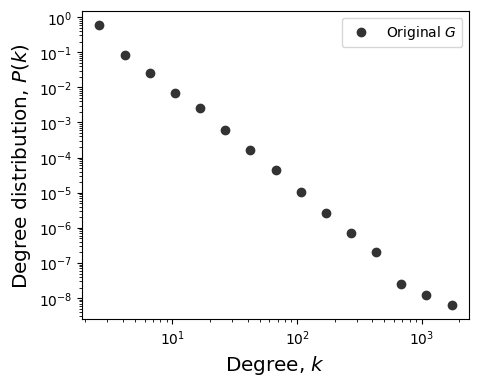

In [5]:
# 2. Plot degree distribution of G
fig, ax = plt.subplots(1,1,figsize=(5,4),dpi=100)
plt.subplots_adjust(wspace=0.25)

# is_pmf=False gives a density, so a power law P(k) ~ k^(-gamma) has slope -gamma on this plot.
# A density can be above 1 at small k, where a log bin is narrower than 1.
x, y = get_binning(list(dict(G.degree()).values()),
                   num_bins=15, log_binning=True, is_pmf=False)

ax.loglog(x,y,'o',color='.2', label=r'Original $G$')
ax.set_ylabel(r'Degree distribution, $P(k)$',fontsize='x-large')
ax.set_xlabel(r'Degree, $k$',fontsize='x-large')

# p = 0.2
# G_s02 = sample_subgraph_random_nodes(G, p, seed=9)
# x_s02, y_s02 = get_binning(list(dict(G_s02.degree()).values()),
#                    num_bins=15, log_binning=True, is_pmf=False)

# ax.loglog(x_s02,y_s02,'s',color='palevioletred', label=r'$G_s$ (p=0.2)',mec='.9')

# p = 0.8
# G_s08 = sample_subgraph_random_nodes(G, p, seed=9)
# x_s08, y_s08 = get_binning(list(dict(G_s08.degree()).values()),
#                    num_bins=15, log_binning=True, is_pmf=False)

# ax.loglog(x_s08,y_s08,'s',color='crimson', label=r'$G_s$ (p=0.8)',mec='.9')


ax.legend()


plt.show()

### Your turn: Create a function to create G_s as described in Fig. 1 above

In [6]:
# 3. YOUR TURN!

def sample_subgraph_random_nodes(G, p=0.2):
    """
    Random node sampling:
      - keep each node independently with probability p
      - return the induced subgraph on the kept nodes, G_s
    """

    pass
    
    
    return G_s

In [7]:
pass

you have 5 minutes

____________

In [8]:
def sample_subgraph_random_nodes(G, p, seed=None):
    """
    Random node sampling:
      - keep each node independently with probability p
      - return the induced subgraph on the kept nodes
    """
    rng = np.random.default_rng(seed)
    nodes = [n for n in G.nodes if rng.random() < p]
    return G.subgraph(nodes).copy()

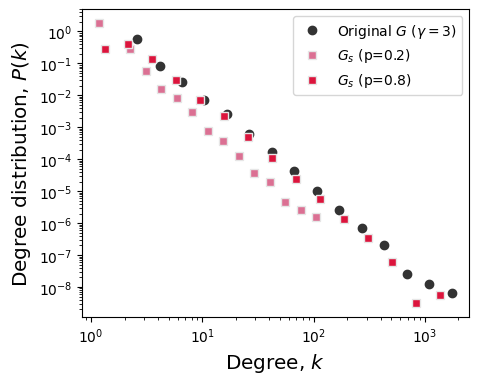

In [9]:
# 2. Plot degree distribution of G
fig, ax = plt.subplots(1,1,figsize=(5,4),dpi=100)
plt.subplots_adjust(wspace=0.25)

x, y = get_binning(list(dict(G.degree()).values()),
                   num_bins=15, log_binning=True, is_pmf=False)

ax.loglog(x,y,'o',color='.2', label=r'Original $G$ ($\gamma=3$)')
ax.set_ylabel(r'Degree distribution, $P(k)$',fontsize='x-large')
ax.set_xlabel(r'Degree, $k$',fontsize='x-large')

p = 0.2
G_s02 = sample_subgraph_random_nodes(G, p, seed=9)
x_s02, y_s02 = get_binning(list(dict(G_s02.degree()).values()),
                   num_bins=15, log_binning=True, is_pmf=False)

ax.loglog(x_s02,y_s02,'s',color='palevioletred', label=r'$G_s$ (p=0.2)',mec='.9')

p = 0.8
G_s08 = sample_subgraph_random_nodes(G, p, seed=9)
x_s08, y_s08 = get_binning(list(dict(G_s08.degree()).values()),
                   num_bins=15, log_binning=True, is_pmf=False)

ax.loglog(x_s08,y_s08,'s',color='crimson', label=r'$G_s$ (p=0.8)',mec='.9')


ax.legend()


plt.show()

### Why does this happen?

A node we keep had $k$ neighbors in $G$, and each of them was kept with probability $p$, independently. So its degree in $G_s$, $k_s$, is a binomial draw, and the degree distribution of $G_s$ is

$$P_s(k_s) = \sum_{k \geq k_s} P(k) \binom{k}{k_s} p^{k_s} (1-p)^{k-k_s} .$$

Let's compute this from the original $P(k)$ and draw it on top of the samples.

p = 0.2: 51% of the kept nodes have no edges left in G_s


p = 0.8: 2% of the kept nodes have no edges left in G_s


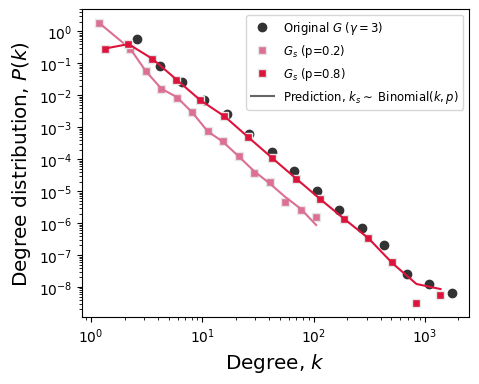

In [10]:
from scipy import stats

# P(k) of the original graph, one entry for each degree k = 0, 1, 2, ...
degrees_G = np.array(list(dict(G.degree()).values()))
P_k = np.bincount(degrees_G) / len(degrees_G)
k_values = np.arange(len(P_k))

fig, ax = plt.subplots(1,1,figsize=(5,4),dpi=100)
ax.loglog(x,y,'o',color='.2', label=r'Original $G$ ($\gamma=3$)')

for p, G_s, col in [(0.2, G_s02, 'palevioletred'), (0.8, G_s08, 'crimson')]:
    degrees_s = np.array(list(dict(G_s.degree()).values()))
    x_s, y_s = get_binning(degrees_s, num_bins=15, log_binning=True, is_pmf=False)
    ax.loglog(x_s, y_s, 's', color=col, label=r'$G_s$ (p=%.1f)' % p, mec='.9')

    # predicted P_s(k_s) for k_s = 0, 1, 2, ...
    P_s = np.array([np.sum(P_k * stats.binom.pmf(k_s, k_values, p)) for k_s in k_values])

    # put the prediction in the same log bins that get_binning used (it leaves out degree 0)
    bin_edges = np.logspace(np.log10(degrees_s[degrees_s > 0].min()), np.log10(degrees_s.max()), 16)
    mass, _ = np.histogram(k_values[1:], bins=bin_edges, weights=P_s[1:])
    density = mass / mass.sum() / np.diff(bin_edges)
    centers = bin_edges[1:] - np.diff(bin_edges) / 2
    ax.loglog(centers[density > 0], density[density > 0], '-', color=col)

    print('p = %.1f: %.0f%% of the kept nodes have no edges left in G_s' % (p, 100*np.mean(degrees_s == 0)))

ax.plot([], [], '-', color='.4', label=r'Prediction, $k_s \sim$ Binomial$(k, p)$')
ax.set_ylabel(r'Degree distribution, $P(k)$',fontsize='x-large')
ax.set_xlabel(r'Degree, $k$',fontsize='x-large')
ax.legend(fontsize='small')

plt.show()

The lines go through the samples. Far out in the tail, $k_s \approx pk$, so the tail is the original one moved to the left, with about the same slope. For small $k$ the binomial spreads the degrees out and bends the curve, which is why the sample doesn't look like a clean power law. And at $p = 0.2$ about half of the kept nodes have no edges left at all (printed above). `get_binning` drops nodes with degree 0, so they aren't in the plot.

Still to do, on your own time: Measure the degree exponent of $G_s$

_________

## Classes of Sampling Methods

Today we'll look at seven sampling designs. They fall into three groups, depending on what gets picked at random:
1. ***Node selection***: a subset of nodes is sampled (Method 1, induced subgraph sampling, and Method 4, star sampling);
2. ***Edge selection***: a subset of edges is sampled (Method 2, incident subgraph sampling, and Method 3, edge sampling with graph induction);
3. ***Topology-based sampling*** (exploration sampling): the topology of the population graph is used to extract the sampled graph (Method 5, snowball sampling; Method 6, traceroute sampling; and Method 7, random walks).

Here are all seven on the same small graph. Red is what ends up in the sample (the black rings mark the starting nodes, which are in the sample too), and bigger dots are nodes with higher degree, so you can see which methods land on the hubs.

![](images/sampling_methods_side_by_side.png)

Two different things can go wrong when we sample, and it helps to keep them apart for the rest of class.

1. **Which nodes we pick.** Some methods pick some nodes more often than others. Edge sampling, snowball sampling and random walks all reach a node through its edges, so a node with more edges gets picked more often. If we look up the true degree of every sampled node, high-degree nodes are over-represented.
2. **What we see about the nodes we picked.** A sampled node usually keeps only some of its edges in $G_s$, so the degree we measure in $G_s$ is lower than its degree in $G$.

In the Stumpf et al. challenge, every node had the same chance of being kept, so only the second problem showed up. Every degree plot below shows one of these: either the degree in $G$ of the sampled nodes, or the degree seen in $G_s$. Check which one before you read the plot.

____________
Final note: a lot of the motivation behind this class comes from the (phenomenal) book, specifically Chapter 5:
- Kolaczyk, E. D. (2009). Sampling and estimation in network graphs. In Statistical Analysis of Network Data: Methods and Models (pp. 1-30). New York, NY: Springer New York. https://link.springer.com/book/10.1007/978-0-387-88146-1

![](images/kolaczyk.png)

___________

## Method 1: Induced Subgraph Sampling

![](images/induced_subgraph_sampling.png)



***Induced subgraph sampling*** consists of drawing at random $n$ vertices from a graph of size $N$. In particular, let us denote with $G = (V,E)$ the original graph and with $G_s = (V_s,E_s)$ the sampled subgraph. Then, the set $V_s$ includes the $n$ nodes randomly drawn from $V$ and $E_s$ contains all the edges $e_{i,j}$ such that both $i$ and $j$ belong to $V_s$.

In this case, the _vertex inclusion probability_ is equal to $\pi_i = \frac{n}{N};$ while the _edge inclusion probability_ is equal to $ \pi_{e_{i,j}} = \frac{n(n-1)}{N(N-1)}$, $\forall i \in V$, and $\forall e_{i,j} \in E$.

#### Vertex inclusion probability - proof

Given that our sample size is $n$, we can extract up to $\binom{N}{n}$ different samples if we do not impose any constraint on whether or not a specific node is selected. However, if we do impose that node $i$ has to be included, then the total number of possible samples becomes $\binom{N-1}{n-1}$.

Therefore, the vertex inclusion probability of a generic node $i$ is:

$$ \pi_i = \frac{\binom{N-1}{n-1}}{\binom{N}{n}} = \frac{\frac{(N-1)!}{(n-1)!(N-n)!}}{\frac{N!}{n!(N-n)!}} = \frac{(N-1)!}{(n-1)!} \frac{n!}{N!} = \frac{n}{N} $$

#### Edge inclusion probability - proof

Edge $e_{i,j}$ is in $G_s$ only if both $i$ and $j$ are picked. If we impose that both nodes have to be included, the number of possible samples becomes $\binom{N-2}{n-2}$. Therefore:

$$ \pi_{e_{i,j}} = \frac{\binom{N-2}{n-2}}{\binom{N}{n}} = \frac{(N-2)!}{(n-2)!} \frac{n!}{N!} = \frac{n(n-1)}{N(N-1)} $$

In [11]:
N = 1000
M = 50000
average_degree = 2*M/N
print(average_degree)

p = average_degree/(N-1)
G_er = nx.erdos_renyi_graph(N,p)
G_ws = nx.watts_strogatz_graph(N, int(average_degree), p=0.01)

print("Average degree ER:", np.mean(list(dict(G_er.degree()).values())))
print("Average degree WS:",  np.mean(list(dict(G_ws.degree()).values())))

100.0
Average degree ER: 100.57
Average degree WS: 100.0


In [12]:
from numpy.random import choice

In [13]:
def induced_subgraph_sampling(G, n):
    """
    Samples an induced subgraph of `n` nodes from the input graph `G`.
    
    Parameters
    ----------
    G : networkx.Graph
        The input graph from which the subgraph is sampled.
    n : int
        The number of nodes to include in the sampled induced subgraph.
    
    Returns
    -------
    subgraph : networkx.Graph
        The induced subgraph with `n` nodes and the edges among them.
        
    Raises
    ------
    ValueError
        If `n` is larger than the number of nodes in the graph.
    """
    # Ensure `n` is not larger than the number of nodes in G
    if n > G.number_of_nodes():
        raise ValueError("`n` must be less than or equal to the number of nodes in the graph.")
    
    # Get the list of nodes in the graph
    nodes = list(G.nodes())
    
    # Randomly sample `n` nodes without replacement
    sampled_nodes = np.random.choice(nodes, size=n, replace=False)
    
    # Create an induced subgraph of G using the sampled nodes
    subgraph = G.subgraph(sampled_nodes).copy()
    
    return subgraph

In [14]:
pos = nx.circular_layout(G_ws)

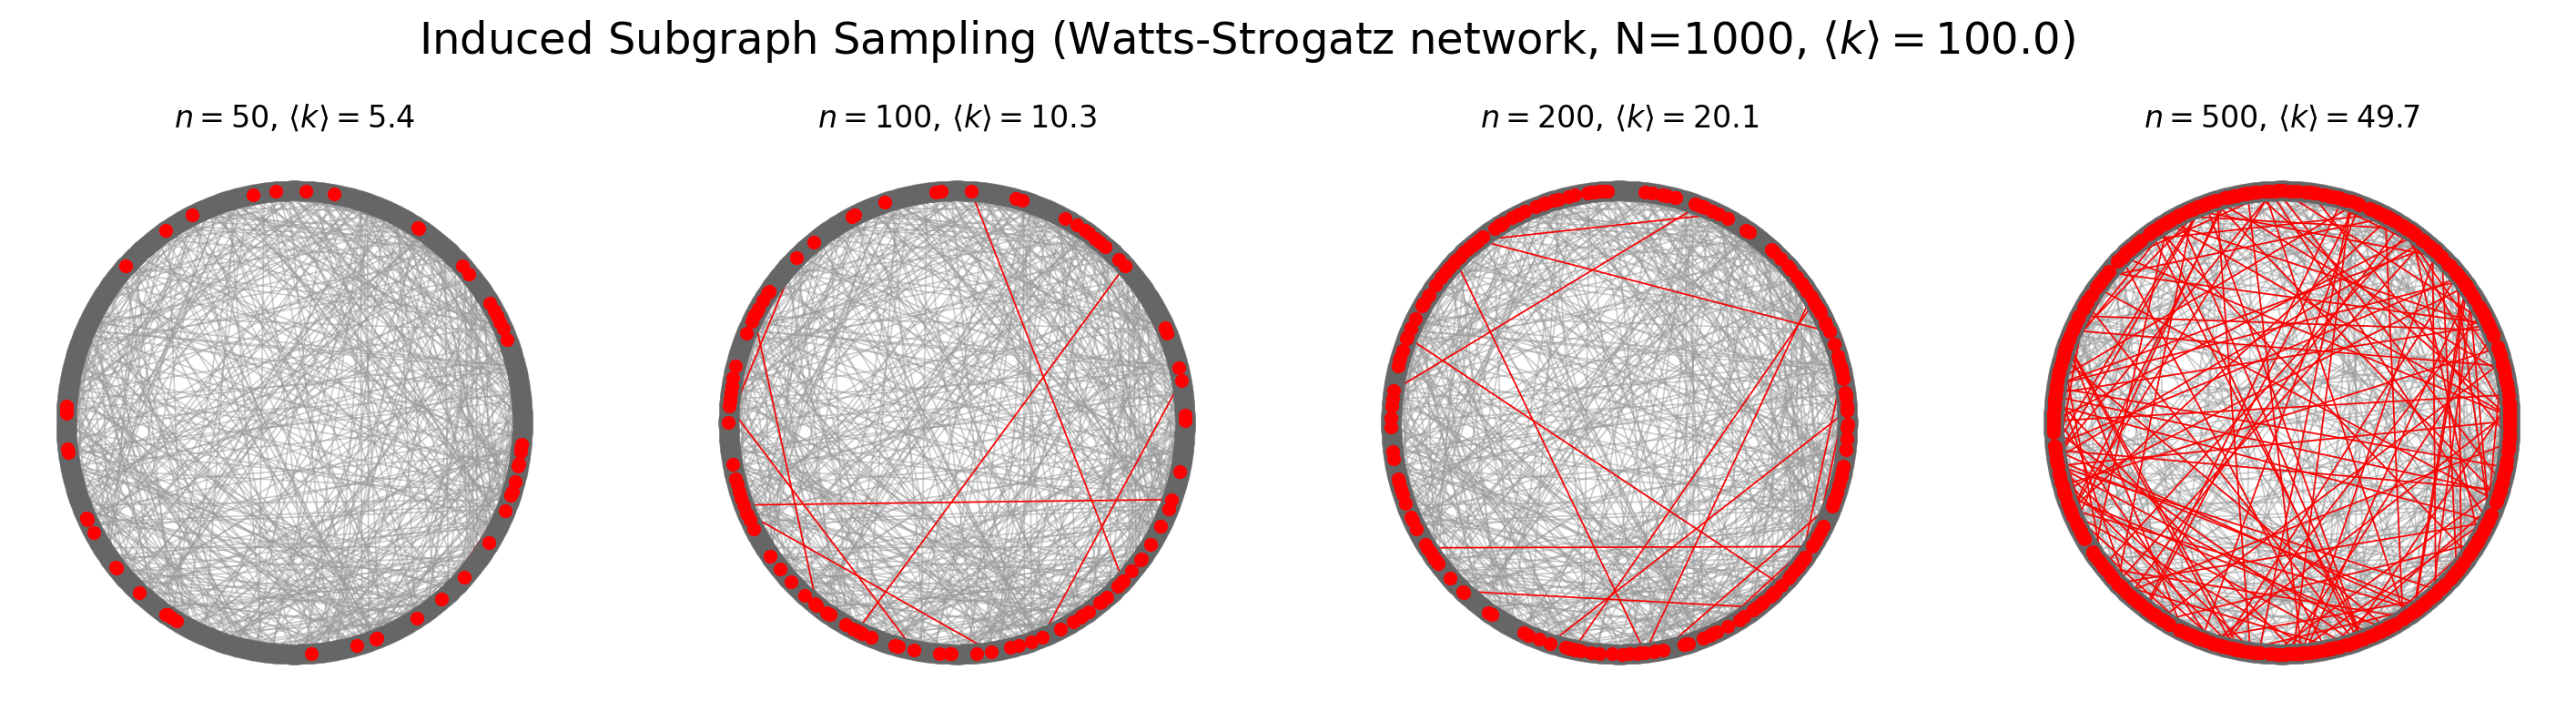

In [15]:
fig, ax = plt.subplots(1,4,figsize=(18,4),dpi=200)

for ni,n in enumerate([50,100,200,500]):
    subg = induced_subgraph_sampling(G_ws, n)
    nx.draw(G_ws, pos, node_color='.4', node_size=50, alpha=0.5, edge_color='.6', width=0.6, ax=ax[ni])
    nx.draw(subg, pos, node_color='red',node_size=20, edge_color='red', width=0.6, ax=ax[ni])
    ax[ni].set_title(r'$n = %i$, $\langle k \rangle = %.1f$'%(n, np.mean(list(dict(subg.degree).values()))))

plt.suptitle(r'Induced Subgraph Sampling (Watts-Strogatz network, N=%i, $\langle k \rangle = %.1f$)'%(
    G_ws.number_of_nodes(),average_degree),
             y=1.05, fontsize='xx-large')
plt.show()

Notice the $\langle k \rangle$ in each panel title. A sampled node keeps an edge only if the node on the other end was picked too, which happens with probability about $n/N$. So the average degree we see is about $(n/N)\langle k \rangle$: about 5 for $n = 50$ and about 50 for $n = 500$. Every node had the same chance of being picked, so this is only the second problem from above: the smaller the sample, the smaller the share of each node's edges we see.

### Statistics note: The Horvitz-Thompson Estimator

The idea behind this estimator: a unit that had probability $\pi_i$ of being sampled stands in for $1/\pi_i$ units. If every node had a 10% chance of being picked, each node we see counts for 10.

Let $U$ be a population of size $N$ (e.g. Facebook users, Twitter users, etc..) and let $y_i$ be a variable of interest associated to each individual $i$ in the population $U$ (e.g. number of friends, number of followers, etc..). Let us denote with $\tau$ the total and with $\mu$ the average of the $y_i$'s values, i.e. $\tau = \sum_i y_i$ and $\mu = \tau/N$. Let us also denote with $S$ a sample of $n$ units from population $N$ and assume that for each unit $i$ in sample $S$ we observe the value $y_i$. Then, we can use the ***Horvitz-Thompson estimator*** to estimate the value of $\tau$ and $\mu$ from the random sample $S$:

$$ \hat{\tau}_\pi = \sum_{i \in S} \frac{y_i}{\pi_i} ,$$

$$ \hat{\mu}_\pi = \frac{\hat{\tau}_\pi }{N} ,$$

where $\pi_{i}$ denotes the _inclusion probability_ of unit $i$ in the sample $S$.

___________

#### Estimate the average degree of the graph from the sampled graph

To estimate $M$ we can use the ***Horvitz-Thompson estimator***:
1. Our individual $i$ is the edge $e_{i,j}$ 
2. The total we want to estimate is: $\tau = M =  \sum_i y_i = \sum_{e_{i,j}}1$
3. In our case, the edge inclusion probability is (from the proof above): $ \pi_{e_{i,j}} = \frac{n(n-1)}{N(N-1)} ,$
4. Therefore we can estimate $\hat{M}$ as: $ \hat{\tau}_\pi = \sum_{e_{i,j} \in S} \frac{1}{\pi_{e_{i,j}}} = M_s\frac{N(N-1)}{n(n-1)}$

Then, we can compute $\hat{k}$ as: $\hat{k} = \frac{2\hat{M}}{N}$.

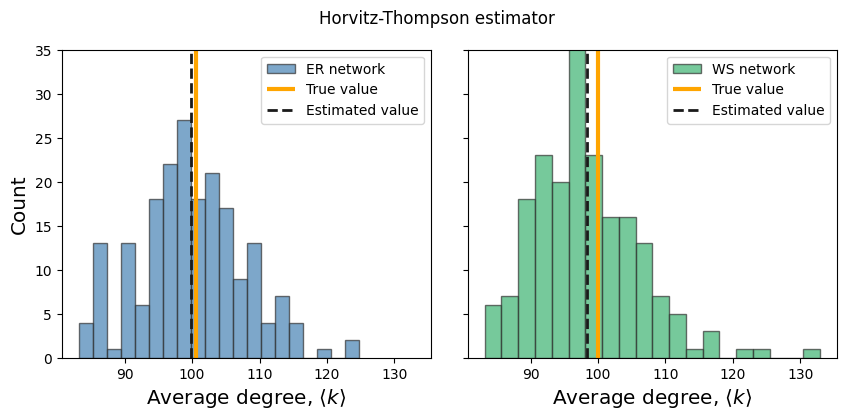

In [16]:
fig, ax = plt.subplots(1,2,figsize=(10,4),dpi=100,sharey=True,sharex=True)
plt.subplots_adjust(wspace=0.1)
cols = ['steelblue','mediumseagreen']
    
B = 200 # number of simulations
labels = ['ER','WS']
for a, G in enumerate([G_er, G_ws]):
    av_degs = np.zeros(B)
    for b in range(B):
        n = 50
        subg_G = induced_subgraph_sampling(G, n)
        m = subg_G.number_of_edges()
        prob_e = n*(n-1)/N/(N-1)
        M_est = m/prob_e
        av_degs[b] = 2*M_est/N


    ax[a].hist(av_degs, 20, label=labels[a]+" network", color=cols[a], ec='.2', alpha=0.7)
    degs_G = np.mean(list(dict(G.degree()).values()))
    ax[a].vlines(degs_G, 0, 35, lw=3, label='True value', color='orange')

    mu = np.mean(av_degs)
    ax[a].vlines(mu, 0, 35, color='.1', lw=2, label='Estimated value', ls='--')
    ax[a].legend()
    ax[a].set_ylim(0,35)
    ax[a].set_xlabel(r'Average degree, $\langle k \rangle$', fontsize='x-large')

ax[0].set_ylabel('Count', fontsize='x-large')

plt.suptitle('Horvitz-Thompson estimator')

plt.show()

### Estimating the number of nodes

To estimate the number of nodes of a graph from a sampled graph we can use the following ***capture-recapture*** estimator:
1. We sample two distinct graphs using the induced subgraph sampling design and we denote the number of nodes in the two graphs with $n_1$ and $n_2$, respectively;
2. We count the number of nodes that the two sampled graphs have in common (we denote this number with $n_c$);
3. We estimate the number of nodes in the original graph using the estimator
$ \hat{N} = \frac{n_1 n_2}{n_c}$.

Why does this work? Sample 1 contains a share $n_1/N$ of all the nodes. Sample 2 is drawn independently of sample 1, so about the same share of sample 2 should already be in sample 1: $n_c/n_2 \approx n_1/N$. Solving for $N$ gives the estimator. Notice that it doesn't use the edges at all. Ecologists count the fish in a lake this way: catch some, tag them, let them go, and count how many tagged fish turn up in a second catch.

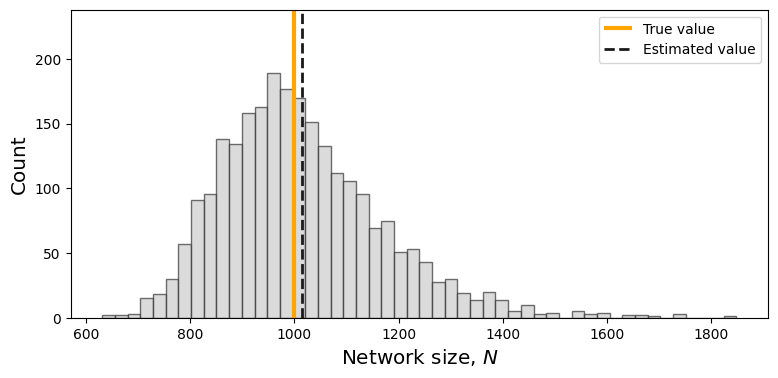

In [17]:
B = 2500  # Number of iterations
N = 1000  # True size of the network

nodes = list(range(N))  

# Array to store network size estimates
N_est = np.zeros(B)

### Perform capture-recapture simulation
for b in range(B):
    # Randomly sample the size of the first and second sample sets
    n1 = np.random.randint(150, 200)
    n2 = np.random.randint(150, 200)
    
    # Randomly select nodes for the first and second samples
    V_s1 = np.random.choice(nodes, size=n1, replace=False)
    V_s2 = np.random.choice(nodes, size=n2, replace=False)
    
    # Count the number of nodes in the intersection (recaptured nodes)
    n_c = len(set(V_s1).intersection(V_s2))
    
    # Estimate the network size if recaptured nodes exist; otherwise, set to NaN
    N_est[b] = n1 * n2 / n_c if n_c > 0 else np.nan


# Filter out invalid estimates (NaN values)
N_est = N_est[np.isfinite(N_est)]

#################

fig, ax = plt.subplots(1, 1, figsize=(9, 4), dpi=100)
ax.hist(N_est, bins=50, color='.8', edgecolor='.2', alpha=0.7)
# ax.set_yticks(range(0,25,5))
ax.set_ylim(0)
ylims = ax.get_ylim()

ax.vlines(N, 0, ylims[1]*1.2, linewidth=3, label='True value', color='orange')

mu = np.mean(N_est)
ax.vlines(mu, 0, ylims[1]*1.2, color='.1', linewidth=2, label='Estimated value', linestyle='--')

ax.set_ylim(0, ylims[1]*1.2)
ax.legend()
ax.set_ylabel('Count',fontsize='x-large')
ax.set_xlabel(r'Network size, $N$',fontsize='x-large')


plt.show()

(That is very cool!)

Notice that the dashed line sits a little to the right of the true value. $n_1 n_2 / n_c$ runs slightly high on average, about 2% here, because $n_c$ is a small number that changes from run to run, and dividing by it pushes the average up. Chapman's version, $\hat{N} = \frac{(n_1+1)(n_2+1)}{n_c+1} - 1$, removes almost all of that.

How big do the two samples need to be? Let's try a network of $N$ = 10,000 nodes and samples of different sizes.

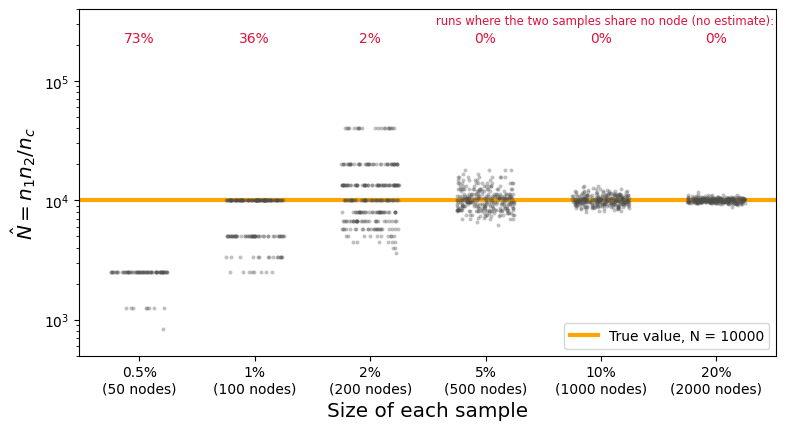

In [18]:
N = 10000
fracs = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2]   # size of each sample, as a share of N
n_runs = 300

fig, ax = plt.subplots(1, 1, figsize=(9, 4.5), dpi=100)
for i, f in enumerate(fracs):
    n1 = n2 = int(f*N)
    N_est = []
    no_overlap = 0
    for _ in range(n_runs):
        V_s1 = np.random.choice(N, size=n1, replace=False)
        V_s2 = np.random.choice(N, size=n2, replace=False)
        n_c = len(set(V_s1).intersection(V_s2))
        if n_c > 0:
            N_est.append(n1*n2/n_c)
        else:
            no_overlap += 1

    # spread the dots out sideways so they don't sit on top of each other
    ax.scatter(i + np.random.uniform(-0.25, 0.25, len(N_est)), N_est, s=8, color='.3', alpha=0.35, lw=0)
    ax.text(i, 2.1e5, '%i%%' % round(100*no_overlap/n_runs), ha='center', color='crimson')

ax.text(len(fracs)-0.5, 3.0e5, 'runs where the two samples share no node (no estimate):',
        ha='right', fontsize='small', color='crimson')
ax.axhline(N, color='orange', lw=3, label='True value, N = %i' % N, zorder=0)
ax.set_yscale('log')
ax.set_ylim(500, 4e5)
ax.set_xticks(range(len(fracs)))
ax.set_xticklabels(['%g%%\n(%i nodes)' % (100*f, int(f*N)) for f in fracs])
ax.set_xlabel('Size of each sample', fontsize='x-large')
ax.set_ylabel(r'$\hat{N} = n_1 n_2 / n_c$', fontsize='x-large')
ax.legend(loc='lower right')

plt.show()

Each dot is one run. With samples of 0.5% of the nodes (50 each), the two samples share no node in most runs (the red numbers), so there's no estimate at all, and the runs that do share a node or two say $\hat{N}$ = 2,500 or less. By 5% the estimates are centered on the truth, and by 20% they are tight around it. The estimator needs the samples to overlap, and they only overlap reliably when the expected overlap, $n_1 n_2 / N$, is well above 1.

_________
## Method 2: Incident Subgraph Sampling
![](images/incident_subgraph_sampling.png)

***Incident subgraph sampling*** involves drawing $n$ *edges* at random from a graph of size $N$. Let us denote with $G = (V,E)$ the original graph and with $G_s = (V_s,E_s)$ the sampled subgraph. Then, the set $E_s$ includes the $n$ edges randomly selected from $E$ and $V_s$ contains all the nodes incident to the selected edges such that $\forall e_{i,j} \in E_s$, $i,j \in V_s$.

In this case, the _vertex inclusion probability_ is equal to:

$$ \pi_i =   \begin{cases} 1 - \frac{\binom{M - k_i}{n}}{\binom{M}{n}}, \text{ if } n\leq M - k_i\\ 
1, \text{ if } n > M - k_i \end{cases}
$$

while the *edge inclusion probability* is equal to:

$$ \pi_{e_{i,j}} = \frac{n}{M} ,$$

$\forall i \in V$, and $\forall e_{i,j} \in E$.

Here $M$ is the number of edges and $k_i$ is the degree of node $i$. Notice that $\pi_i$ is computed as one minus the probability of **not** sampling an edge incident to $i$: there are $\binom{M-k_i}{n}$ ways to pick $n$ edges that all miss node $i$. A node with 50 edges gets 50 chances to be included, so edge sampling picks high-degree nodes more often. That's the first problem from above.

In [19]:
from random import shuffle

def incident_subgraph_sampling(G, n, is_directed=False):
    """
    Samples an incident subgraph containing `n` edges from the input graph `G`.
    
    Parameters
    ----------
    G : networkx.Graph or networkx.DiGraph
        The input graph from which the subgraph is sampled.
    n : int
        The number of edges to include in the sampled incident subgraph.
    is_directed : bool, optional (default=False)
        Specifies if the graph is directed. If True, edges are treated as directed.
        
    Returns
    -------
    subgraph : networkx.Graph or networkx.DiGraph
        The incident subgraph with `n` edges and the nodes connected by those edges.
        
    Raises
    ------
    ValueError
        If `n` is larger than the number of edges in the graph.
    """
    # Ensure `n` is not larger than the number of edges in G
    if n > G.number_of_edges():
        raise ValueError("`n` must be less than or equal to the number of edges in the graph.")
    
    # Get the list of edges in the graph
    edges = list(G.edges())
    
    # Shuffle the edges randomly to sample from them
    shuffle(edges)
    
    # Select the first `n` edges from the shuffled list
    sampled_edges = edges[:n]
    
    # Find the unique nodes connected by the sampled edges
    sampled_nodes = set(node for edge in sampled_edges for node in edge)
    
    # Create a new subgraph with the sampled nodes and edges
    subgraph = G.edge_subgraph(sampled_edges).copy()
    
    return subgraph

### Let's look at an example where we randomly assign nodes to group labels in a network

Is our approach able to correctly estimate the number of red and blue nodes?

In [20]:
N = 1000
G = nx.barabasi_albert_graph(N,10)
pos = nx.spring_layout(G)
print("Average degree: %1.1f" % np.mean(list(dict(G.degree()).values())))
M = G.number_of_edges()
print("Number of edges:", M)

Average degree: 19.8
Number of edges: 9900


Number of red nodes: 681
Number of blue nodes: 319


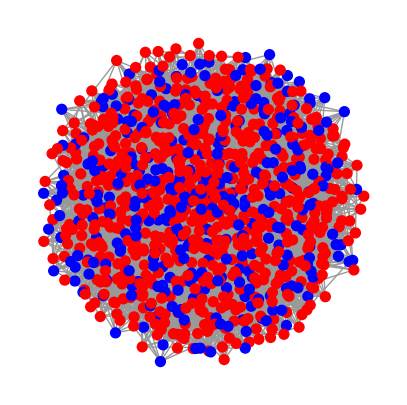

In [21]:
prob_red = 0.7
reds = 0
blues = 0
for node in G.nodes():
    G.nodes[node]['team'] = 'red' if np.random.rand() < prob_red else 'blue'
    if G.nodes[node]['team'] == 'red':
        reds += 1
    else:
        blues += 1
        
print("Number of red nodes:",reds)
print("Number of blue nodes:",blues)

fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=100)
nx.draw(G, pos=pos, node_color=nx.get_node_attributes(G, 'team').values(),ax=ax,node_size=50, edge_color='.6')
plt.show()

In [22]:
from scipy.special import binom

def prob_i(M, k_i, n):
    """
    Probability that node i ends up in an incident subgraph sample of n edges.

    Parameters:
    M : int
        Number of edges in the graph.
    k_i : int
        Degree of node i.
    n : int
        Number of sampled edges.

    Returns:
    float
        Inclusion probability of node i, 1 - binom(M - k_i, n) / binom(M, n).
    """
    # If fewer than n edges miss node i, every sample of n edges includes one of its edges.
    if n > M - k_i:
        return 1.0

    # Otherwise, one minus the probability that none of the n sampled edges touches node i.
    return 1.0 - binom(M - k_i, n) / binom(M, n)

In [23]:
# We use the Horvitz-Thompson estimator to get those numbers from sampled graphs
B = 1000
reds_est = [None]*B
blues_est = [None]*B
degrees = dict(G.degree())

for b in range(B):
    n = 100
    G_s = incident_subgraph_sampling(G,n)
    V_s = list(G_s.nodes())
    E_s = list(G_s.edges())
    pi = {node: prob_i(M,degrees[node],n)  for node in V_s}
    reds_est[b] = sum([ 1.0/pi[node] for node in V_s if G.nodes[node]['team'] == 'red'])
    blues_est[b] = sum([ 1.0/pi[node] for node in V_s if G.nodes[node]['team'] == 'blue'])

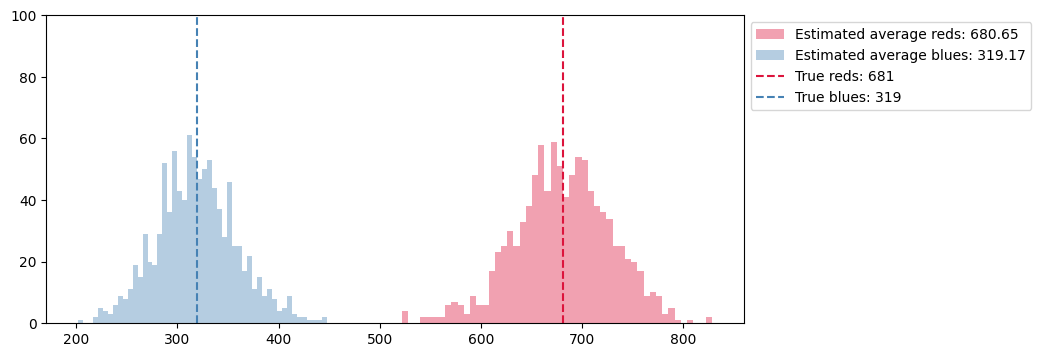

In [24]:
fig, ax = plt.subplots(1,1,figsize=(9,4),dpi=100)

ax.hist(reds_est, bins=50, color='crimson', alpha=0.4,
        label='Estimated average reds: %.2f'%(np.mean(reds_est)))
ax.hist(blues_est, bins=50, color='steelblue', alpha=0.4,
        label='Estimated average blues: %.2f'%(np.mean(blues_est)))

ax.vlines(reds, 0, 100, color='crimson', ls='--', label='True reds: %i'%reds)
ax.vlines(blues, 0, 100, color='steelblue', ls='--', label='True blues: %i'%blues)

ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_ylim(0,100)

plt.show()

### Do we need the $1/\pi_i$ weights?

A simpler guess would be the share of red nodes in the sample, scaled up to $N$. Let's compare that naive estimate with Horvitz-Thompson, first with the random labels from above, then with labels tied to degree: in a BA graph the oldest nodes have the most edges, so on the right we call the 300 oldest nodes red.

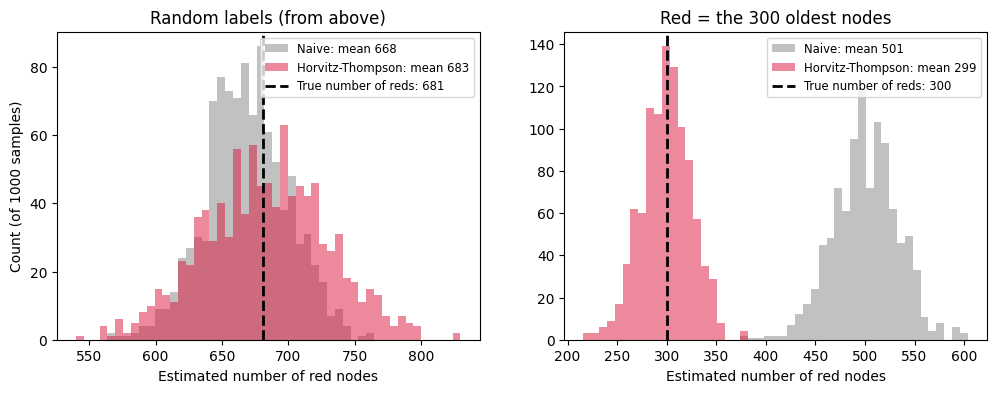

In [25]:
# Same graph, two ways of labeling the nodes red
is_red = {'Random labels (from above)': {node: G.nodes[node]['team'] == 'red' for node in G.nodes()},
          'Red = the 300 oldest nodes': {node: node < 300 for node in G.nodes()}}

fig, ax = plt.subplots(1, 2, figsize=(12, 4), dpi=100)
for a, (title, red) in enumerate(is_red.items()):
    naive_est = []
    ht_est = []
    for b in range(B):
        V_s = list(incident_subgraph_sampling(G, n).nodes())
        # naive: the share of red nodes in the sample, scaled up to N
        naive_est.append(sum([red[node] for node in V_s]) / len(V_s) * N)
        # Horvitz-Thompson: each sampled red node counts for 1/pi_i
        ht_est.append(sum([1.0/prob_i(M, degrees[node], n) for node in V_s if red[node]]))

    bins = np.linspace(min(naive_est + ht_est), max(naive_est + ht_est), 50)
    ax[a].hist(naive_est, bins, color='.6', alpha=0.6, label='Naive: mean %.0f' % np.mean(naive_est))
    ax[a].hist(ht_est, bins, color='crimson', alpha=0.5, label='Horvitz-Thompson: mean %.0f' % np.mean(ht_est))
    ax[a].axvline(sum(red.values()), color='k', ls='--', lw=2,
                  label='True number of reds: %i' % sum(red.values()))
    ax[a].set_title(title)
    ax[a].set_xlabel('Estimated number of red nodes')
    ax[a].legend(fontsize='small')
ax[0].set_ylabel('Count (of %i samples)' % B)

plt.show()

With random labels (left), a red node is no more likely to be sampled than a blue one, so even the naive estimate comes close. It can still miss by a few percent, because in any one random labeling the hubs may happen to be a bit more red or a bit more blue than the rest, and edge sampling over-picks the hubs. When the label is tied to degree (right), edge sampling picks the red nodes more often, and the naive estimate counts about 500 reds. Horvitz-Thompson counts each sampled red node as $1/\pi_i$ nodes. The high-degree reds are easy to pick, so each of them counts for less, and the estimate comes out at 300. Notice that Horvitz-Thompson pays for being unbiased: on the left its estimates are more spread out than the naive ones, because a low-degree node that lands in the sample counts for about 10 nodes.

In [26]:
N = 10000
M = 50000
G = nx.gnm_random_graph(N,M)
degrees = list(dict(G.degree()).values())
print("Average degree: %1.3f" % np.mean(degrees))
n = 5000

Average degree: 10.000


In [27]:
# Using Incident Graph Sampling
G_incid = incident_subgraph_sampling(G, n)
degrees_incid = list(dict(G_incid.degree()).values())
x_incid, y_incid = get_binning(degrees_incid, log_binning=True, is_pmf=False, num_bins=15)

In [28]:
# True Degree distribution
x_true, y_true = get_binning(degrees, log_binning=True, is_pmf=False, num_bins=15)

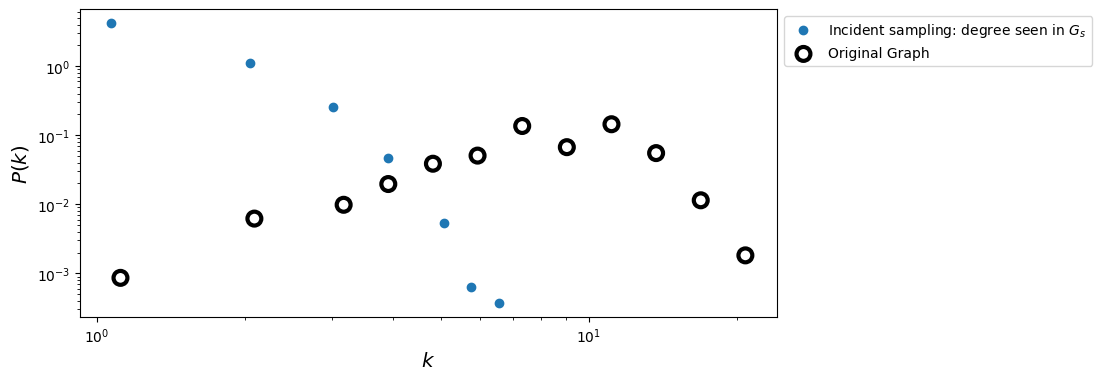

In [29]:
fig, ax = plt.subplots(1,1,figsize=(9,4),dpi=100)

ax.loglog(x_incid, y_incid, 'o', label='Incident sampling: degree seen in $G_s$')
ax.scatter(x_true, y_true, s= 100, facecolors='none', edgecolors='k', lw=3, label = 'Original Graph')

ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_xlabel(r'$k$',fontsize='x-large')
ax.set_ylabel(r'$P(k)$',fontsize='x-large')


plt.show()

Notice that the first point of the sample is above 1. The y-axis is a density: the share of nodes in a bin divided by the width of the bin. More than half of the sampled nodes have degree 1, and the first log bin, from 1 to about 1.1, is narrower than 1, so the density there is above 1.

__________
## Method 3: Edge Sampling with Graph Induction (ES-i)
![](images/ES-i.png)

***Edge Sampling with Graph Induction*** consists of drawing at random $n$ edges from a graph of size $N$. Let us denote with $G = (V,E)$ the original graph and with $G_s = (V_s,E_s)$ the sampled subgraph. Then, $V_s$ contains all the nodes incident to the randomly selected edges and $E_s$ comprises the $n$ edges randomly selected from $E$ plus all the other edges $e_{i,j} \in E$ such that both $i$ and $j$ belong to $V_s$. 


**Source:** Ahmed, N., Neville, J., & Kompella, R. R. (2011). Network sampling via edge-based node selection with graph induction. https://docs.lib.purdue.edu/cstech/1747/

In [30]:
def edge_sampling_with_induction(G, n):
    """
    Perform edge sampling with induction and return a new graph.

    Parameters:
    G : networkx.Graph
        Input graph.
    n : int
        Number of edges to sample initially.

    Returns:
    networkx.Graph
        A new graph induced by the sampled nodes and edges.
    """
    # Get all edges and total number of edges in the graph
    edges = list(G.edges())
    M = G.number_of_edges()
    
    # Sample n edges randomly without replacement
    sampled_edges = set([edges[i] for i in np.random.permutation(M)[:n]])
    
    # Extract the set of nodes in the sampled edges
    nodes_from_sampled_edges = set(node for edge in sampled_edges for node in edge)

    # Induce edges between the sampled nodes
    induced_edges = set(sampled_edges)
    for node_i, node_j in edges:
        if node_i in nodes_from_sampled_edges and node_j in nodes_from_sampled_edges:
            induced_edges.add((node_i, node_j))
    
    # Create a new graph with the sampled nodes and induced edges
    new_graph = nx.Graph()
    new_graph.add_nodes_from(nodes_from_sampled_edges)
    new_graph.add_edges_from(induced_edges)
    
    return new_graph

In [31]:
G_esi = edge_sampling_with_induction(G, n)
degrees_esi = list(dict(G_esi.degree()).values())
x_esi,y_esi = get_binning(degrees_esi, log_binning=True, is_pmf=False, num_bins=15)

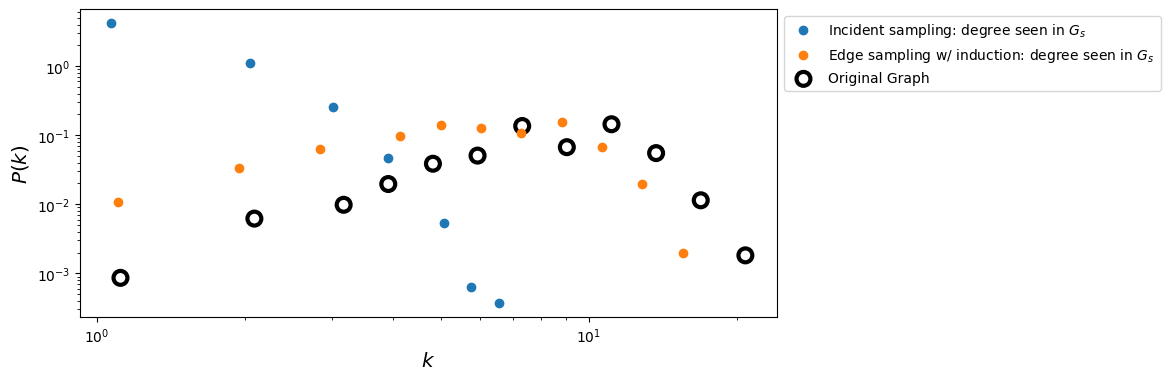

In [32]:
fig, ax = plt.subplots(1,1,figsize=(9,4),dpi=100)

ax.loglog(x_incid, y_incid, 'o', label='Incident sampling: degree seen in $G_s$')
ax.loglog(x_esi, y_esi, 'o', label='Edge sampling w/ induction: degree seen in $G_s$')
ax.scatter(x_true, y_true, s= 100, facecolors='none', edgecolors='k', lw=3, label = 'Original Graph')

ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_xlabel(r'$k$',fontsize='x-large')
ax.set_ylabel(r'$P(k)$',fontsize='x-large')


plt.show()

### But what about in networks with heavy-tail degree distributions?

In [33]:
N = 10000
ba = nx.barabasi_albert_graph(N, 5)
degrees = np.array(list(dict(ba.degree()).values()))
print("Average degree: %1.3f" % np.mean(degrees))
M = ba.number_of_edges()
n = int(M*0.15)

Average degree: 9.995


In [34]:
# Using Edge Sampling with Graph Induction
ba_s = edge_sampling_with_induction(ba,n)
V_s, E_s = ba_s.number_of_nodes(), ba_s.number_of_edges()
degrees_s = np.array(list(dict(ba_s.degree()).values()))

x_s,y_s = get_binning(degrees_s, log_binning=True, is_pmf=False, num_bins=15)

In [35]:
# Using Incident Graph Sampling
ba_s_i = incident_subgraph_sampling(ba,n)
V_s_i, E_s_i = ba_s_i.number_of_nodes(), ba_s_i.number_of_edges()
degrees_s_i = np.array(list(dict(ba_s_i.degree()).values()))

x_s_i,y_s_i = get_binning(degrees_s_i, log_binning=True, is_pmf=False, num_bins=15)

In [36]:
# True Degree distribution
x_t,y_t = get_binning(degrees, log_binning=True, is_pmf=False, num_bins=15)

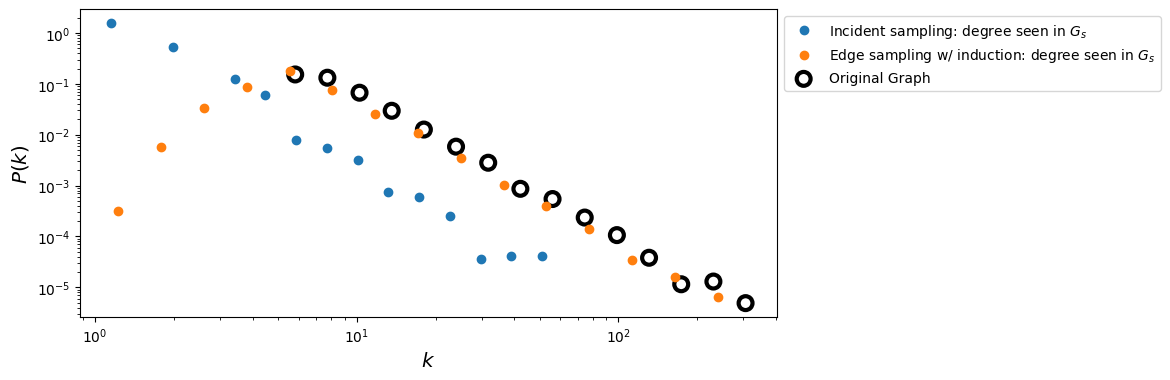

In [37]:
fig, ax = plt.subplots(1,1,figsize=(9,4),dpi=100)

ax.loglog(x_s_i,y_s_i,'o', label = 'Incident sampling: degree seen in $G_s$')
ax.loglog(x_s,y_s,'o', label='Edge sampling w/ induction: degree seen in $G_s$')
ax.scatter(x_t,y_t, s= 100, facecolors='none', edgecolors='k', lw=3, label = 'Original Graph')

ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_xlabel(r'$k$',fontsize='x-large')
ax.set_ylabel(r'$P(k)$',fontsize='x-large')


plt.show()

To put a number on how close two degree distributions are, we can use the **Kolmogorov-Smirnov (KS) statistic**. For each distribution, compute the cumulative distribution: the fraction of nodes with degree at most $k$, for every $k$. The KS statistic $D$ is the largest gap between the two curves. $D = 0$ when the two distributions are identical, and $D = 1$ when they don't overlap at all (every sampled degree is below every original degree, for example).

In [38]:
from scipy.stats import ks_2samp

def ks_d(values1, values2):
    """
    Compute the Kolmogorov-Smirnov (KS) statistic to compare two distributions.

    Parameters:
    values1 : array-like
        First sample of values.
    values2 : array-like
        Second sample of values.

    Returns:
    float
        KS statistic (D), representing the maximum distance between the empirical 
        cumulative distribution functions (ECDFs) of the two samples.
    """
    D, _ = ks_2samp(values1, values2)
    return D

print('Original vs Edge Sampling w/ Induction:\t', ks_d(degrees, degrees_s))
print('Original vs Incident Graph Sampling:\t', ks_d(degrees, degrees_s_i))

Original vs Edge Sampling w/ Induction:	 0.15849163595123333


Original vs Incident Graph Sampling:	 0.9358774294226131


### Why is this working better?

Let's measure the two problems from the start of class separately, on the same BA graph, as we sample a larger and larger share of its edges. For each sample we record the mean degree in $G$ of the sampled nodes (which nodes we pick), and the mean degree we see in $G_s$, with and without the induction step (what we see).

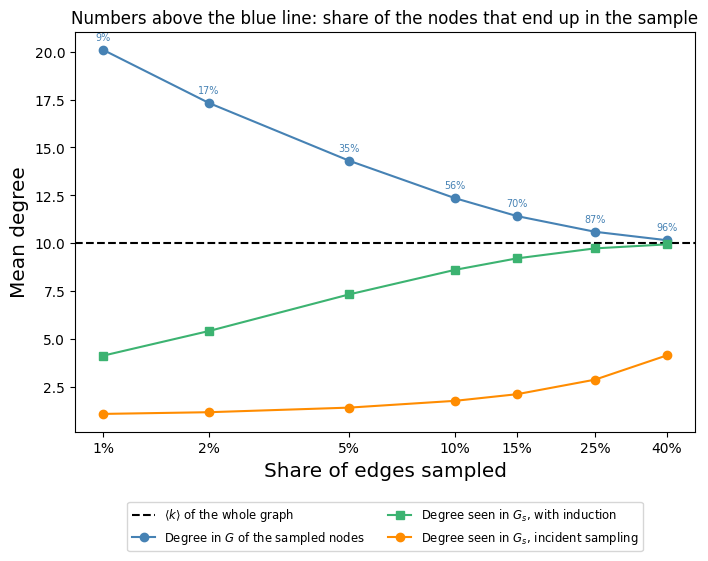

In [39]:
fracs = [0.01, 0.02, 0.05, 0.1, 0.15, 0.25, 0.4]   # share of the edges we sample
n_reps = 5
degree_in_G = dict(ba.degree())

# one row per share: [degree in G, degree seen (incident), degree seen (with induction), share of nodes sampled]
results = []
for f in fracs:
    rows = []
    for rep in range(n_reps):
        G_inc = incident_subgraph_sampling(ba, int(f*M))
        # induction: same nodes, plus every edge of G between them (what edge_sampling_with_induction does)
        G_ind = ba.subgraph(G_inc.nodes())
        V_s = list(G_inc.nodes())
        rows.append([np.mean([degree_in_G[u] for u in V_s]),
                     2*G_inc.number_of_edges()/len(V_s),
                     2*G_ind.number_of_edges()/len(V_s),
                     len(V_s)/ba.number_of_nodes()])
    results.append(np.mean(rows, axis=0))
results = np.array(results)

fig, ax = plt.subplots(1, 1, figsize=(8, 5.2), dpi=100)
ax.axhline(np.mean(degrees), color='k', ls='--', lw=1.5, label=r'$\langle k \rangle$ of the whole graph')
ax.plot(fracs, results[:,0], 'o-', color='steelblue', label='Degree in $G$ of the sampled nodes')
ax.plot(fracs, results[:,2], 's-', color='mediumseagreen', label='Degree seen in $G_s$, with induction')
ax.plot(fracs, results[:,1], 'o-', color='darkorange', label='Degree seen in $G_s$, incident sampling')
for f, row in zip(fracs, results):
    ax.annotate('%.0f%%' % (100*row[3]), (f, row[0]), textcoords='offset points', xytext=(0, 7),
                ha='center', fontsize='x-small', color='steelblue')
ax.set_xscale('log')
ax.minorticks_off()
ax.set_xticks(fracs)
ax.set_xticklabels(['%g%%' % (100*f) for f in fracs])
ax.set_xlabel('Share of edges sampled', fontsize='x-large')
ax.set_ylabel('Mean degree', fontsize='x-large')
ax.set_title('Numbers above the blue line: share of the nodes that end up in the sample')
ax.legend(fontsize='small', loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)

plt.show()

The blue line sits above the dashed line, because edge sampling picks hubs more often. The orange line sits far below it: incident sampling keeps only the edges we picked, so each node is seen with only a few of its edges. The induction step puts back every edge between the sampled nodes, and once we sample 15% or more of the edges, the green line comes close to the truth.

The numbers above the blue line explain why induction looked so good in the degree distributions above. Sampling 15% of the edges already puts about 70% of the nodes in the sample, so most of a sampled node's neighbors are in the sample too, and induction gives it back most of its edges. The sampled nodes also have more edges than average to begin with (the blue line), which makes up for some of the edges that are still missing. With 1% of the edges, only about 10% of the nodes are in the sample, and induction can't recover much.

________
## Method 4: Star Sampling

***Star sampling*** consists of drawing at random $n$ nodes from a graph of order $N$. Let us denote this initial set of nodes with $V_{s0}$. Then, a set of edges $E_s$ is created including all the edges which are incident to the vertices in $V_{s0}$. Then, two different sampling designs can be employed:

1. **Unlabeled star sampling**: the sampled graph is simply $G_s = (V_s,E_s)$ with $V_{s}=V_{s0}$, 

2. **Labeled star sampling**: the sampled graph includes all the nodes $j$ incident to the edges in $E_s$. That is, the original set $V_{s0}$ is extended.  Therefore, the sampled graph is $G_s = (V_s,E_s)$.


In both cases the _edge inclusion probability_ is equal to $ \pi_{e_{i,j}} = 1 - \frac{\binom{N-2}{n}}{\binom{N}{n}}$. An edge is missed only if neither of its endpoints is one of the $n$ starting nodes, and there are $\binom{N-2}{n}$ ways to pick $n$ starting nodes that avoid both.

The _vertex inclusion probabilities_ differ between the two designs (see also Section 5.3.2 in "Statistical Analysis of Network Data: Methods and Models", 2009):
- unlabeled star sampling keeps only the starting nodes, so $\pi_i = \frac{n}{N}$, as in induced subgraph sampling;
- labeled star sampling keeps node $i$ if it is a starting node or if any of its $k_i$ neighbors is, so $\pi_i = 1 - \frac{\binom{N-1-k_i}{n}}{\binom{N}{n}}$. High-degree nodes are more likely to end up in the sample.

____________

In [40]:
def labeled_star_sampling(G, n):
    """
    Labeled star sampling on a NetworkX graph.

    Parameters
    ----------
    G : networkx.Graph or networkx.DiGraph
        Input graph of order N.
    n : int
        Number of nodes to select uniformly at random for V_{s0}.

    Returns
    -------
    G_s : networkx.Graph or networkx.DiGraph
        Sampled graph G_s = (V_s, E_s) where:
        - V_{s0} is a random subset of n nodes,
        - E_s contains all edges incident to nodes in V_{s0},
        - V_s includes V_{s0} plus all neighbors of V_{s0}
          (i.e., labeled star sampling).
    """
    # Handle empty graph
    if G.number_of_nodes() == 0:
        return nx.DiGraph() if G.is_directed() else nx.Graph()

    nodes = list(G.nodes())
    shuffle(nodes)

    # Ensure n doesn't exceed |V|
    n = min(n, len(nodes))

    # Initial random set V_{s0}
    V_s0 = set(nodes[:n])

    # Initialize sampled graph with same directedness as G
    G_s = nx.DiGraph() if G.is_directed() else nx.Graph()

    # Add all edges incident to V_{s0}; NetworkX will automatically
    # include the corresponding endpoint nodes, so this yields V_s.
    for u in V_s0:
        for v in G.neighbors(u):
            G_s.add_edge(u, v)

    # Make sure all sampled centers are present even if isolated
    G_s.add_nodes_from(V_s0)

    return G_s

### Let us use the Political Blogs dataset

In this example, we are going to use a collection of hyperlinks between weblogs on US politics, recorded in 2005 by Adamic and Glance (L. A. Adamic and N. Glance, "The political blogosphere and the 2004 US Election", in Proceedings of the WWW-2005 Workshop on the Weblogging Ecosystem (2005)). We treat the hyperlinks as undirected, so a pair of blogs that link to each other is one edge.

The question we'll ask: how many of the edges connect two blogs with the same political orientation? We can count the true answer in the full graph, so we can check whether star sampling recovers it.

Recall that the data are included in two tab-separated files:
* `polblogs_nodes_class.tsv`: node id, node label, political orientation (0 = left or liberal, 1 = right or conservative).
* `polblogs_edges_class.tsv`: source node id, target node id. 


![](images/glance_adamic.png)

_____


In [41]:
nodes = dict()
with open('data/polblogs_nodes_class.tsv','r') as fp:
    for line in fp:
        node_id, node_label, pol_or = line.strip().split('\t')
        nodes[int(node_id)] = {'label': node_label, 'political': int(pol_or)}  

edges = []
with open('data/polblogs_edges_class.tsv','r') as fp:
    for line in fp:
        source_node_id, target_node_id = map(int,line.strip().split('\t'))
        edges.append((source_node_id, target_node_id))

AG_net = nx.Graph()
AG_net.add_nodes_from(nodes)
AG_net.add_edges_from(edges)

print('Number of edges: %i' % AG_net.number_of_edges())
print('Number of nodes: %i' % AG_net.number_of_nodes())


# count over the graph we sample from (one edge per pair), not the raw rows of the edge file
same_political_orientation = sum([ 1 for node_i,node_j in AG_net.edges() 
                                   if nodes[node_i]['political'] == nodes[node_j]['political'] ])
print("Number of edges connecting blogs with the same political orientation:", same_political_orientation)

Number of edges: 16718
Number of nodes: 1490
Number of edges connecting blogs with the same political orientation: 15143


In [42]:
# helper function for the math
def prob_edge_star(N, n):
    """
    Edge inclusion probability for star sampling with n starting nodes, 1 - binom(N-2, n) / binom(N, n).
    binom(N-2, n) / binom(N, n) simplifies to (N-n)(N-n-1) / (N(N-1)),
    the probability that neither endpoint of the edge is a starting node.
    """
    return 1.0 - (N - n)*(N - n - 1) / (N*(N - 1))

In [43]:
n_iter = 10000
same_political_orientation_est = np.zeros(n_iter)
N = AG_net.number_of_nodes()
M = AG_net.number_of_edges()
N_v = []
N_e = []

for b in range(n_iter):
    n = 30
    G_s = labeled_star_sampling(AG_net, n)
    V_s = list(G_s.nodes())
    E_s = list(G_s.edges())
    prob_eij = prob_edge_star(N, n)
    
    N_v.append(len(V_s))
    N_e.append(len(E_s))
    
    same_political_orientation_est[b] = sum([ 1.0/prob_eij for node_i,node_j in E_s
                                              if nodes[node_i]['political'] == nodes[node_j]['political'] ])

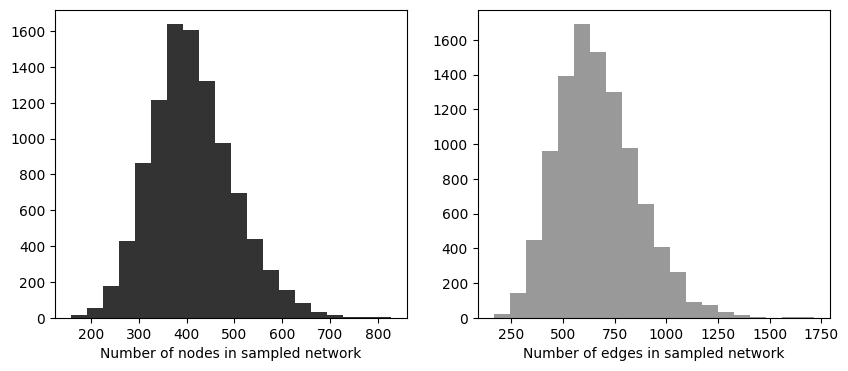

In [44]:
fig, ax = plt.subplots(1,2,figsize=(10,4),dpi=100)
ax[0].hist(N_v,bins=20,color='.2')
ax[1].hist(N_e,bins=20,color='.6')

ax[0].set_xlabel('Number of nodes in sampled network')
ax[1].set_xlabel('Number of edges in sampled network')

plt.show()

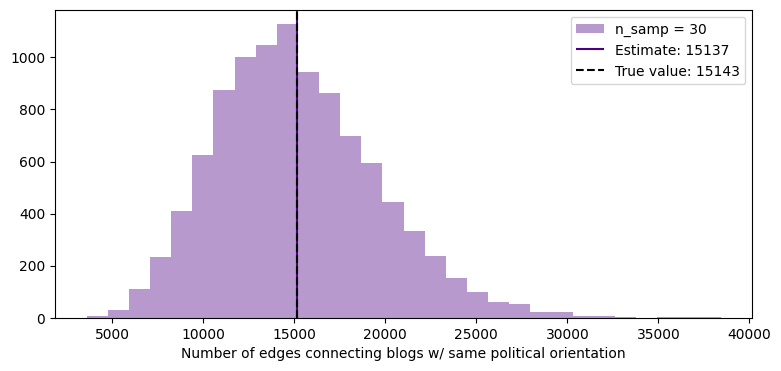

In [45]:
fig, ax = plt.subplots(1,1,figsize=(9,4),dpi=100)

ax.hist(same_political_orientation_est,30,color='indigo', alpha=0.4, label='n_samp = %i'%n)

ylims = ax.get_ylim()
ax.vlines(np.mean(same_political_orientation_est), 0, ylims[1]*1.1, color='indigo', ls='-',
          label="Estimate: %.0f"%np.mean(same_political_orientation_est))
ax.vlines(same_political_orientation, 0, ylims[1]*1.1, color='k', ls='--',
          label="True value: %i"%same_political_orientation)

ax.set_xlabel('Number of edges connecting blogs w/ same political orientation')

ax.legend()
ax.set_ylim(0, ylims[1])


plt.show()

____________
## Method 5: Snowball Sampling
![](images/snowball_sampling.png)

***Snowball sampling*** consists of drawing at random $n$ nodes from a graph of size $N$. Let's denote this initial set of nodes with $V_{s,0}$ and with $\mathbb{V}(S)$ the set of all neighbors of the vertices in a given set $S$. Then, a $k$-wave snowball sampling algorithm simply extends the initial set of nodes $V_{s,0}$ $k$ times in the following way:
* $V_{s,1} = \mathbb{V}(V_{s,0}) \cap \bar{V}_{s,0}$, 
* $V_{s,2} = \mathbb{V}(V_{s,1}) \cap \bar{V}_{s,1} \cap \bar{V}_{s,0}$, 
* ...
* $V_{s,k} = \mathbb{V}(V_{s,k-1}) \cap \bar{V}_{s,k-1} \cap \dots \cap \bar{V}_{s,0}$. 

In words: wave 1 is the neighbors of the seeds that we haven't seen yet, wave 2 is the neighbors of wave 1 that we haven't seen yet, and so on.

Lee, Kim & Jeong (2006) found two things about snowball samples:

1. When the degree distribution of the original network is power-law, it is found that the estimated degree exponent decreases with snowball sampling as we decrease the sampling fraction. 
2. Sampled networks are shown to be more disassortative than the original networks. This pattern is common no matter whether the original network is assortative, disassortative, or neutral.

**Source:** Lee, S. H., Kim, P. J., & Jeong, H. (2006). Statistical properties of sampled networks. *Physical Review E*, 73(1), 016102. https://doi.org/10.1103/PhysRevE.73.016102

In [46]:
def snowball_sampling(G, seed_nodes, n_waves=2):
    """
    Perform snowball sampling on a graph.

    Parameters:
    G : networkx.Graph or networkx.DiGraph
        Input graph.
    seed_nodes : list or set
        Initial set of nodes to start the snowball sampling.
    n_waves : int, optional
        Number of waves to expand the snowball sampling (default is 2).

    Returns:
    networkx.Graph or networkx.DiGraph
        A new graph G_s containing the sampled nodes and edges.
    """
    # Initialize sets to keep track of sampled nodes and edges
    V_s = set(seed_nodes)
    E_s = set()
    
    # Initialize the wave structure
    V = [set()] * (n_waves + 1)
    V[0] = set(seed_nodes)
    
    # Perform snowball sampling over the specified number of waves
    for k in range(n_waves):
        V[k + 1] = set()  # Initialize the next wave
        for node_i in V[k]:
            for node_j in G.neighbors(node_i):
                # Add the edge to the sampled edge set
                edge = (node_i, node_j) if not G.is_directed() and node_i < node_j else (node_i, node_j)
                E_s.add(edge)
                
                # Add the neighboring node to the next wave
                V[k + 1].add(node_j)
        
        # Exclude nodes already in the sampled set
        V[k + 1] -= V_s
        
        # Add new nodes to the sampled set
        V_s.update(V[k + 1])
    
    # Create the new sampled graph
    G_s = G.subgraph(V_s).copy()

    return G_s

In [47]:
N = 15000
m = 3
G = nx.barabasi_albert_graph(N, m)
M = G.number_of_edges()
degrees = list(dict(G.degree()).values())
print("Number of edges:", M)

Number of edges: 44991


Number of waves: 0 | Number of nodes discovered: 50 | Number of edges discovered: 1
Number of waves: 1 | Number of nodes discovered: 445 | Number of edges discovered: 554
Number of waves: 2 | Number of nodes discovered: 4093 | Number of edges discovered: 8945


Number of waves: 3 | Number of nodes discovered: 13702 | Number of edges discovered: 40546


Number of waves: 4 | Number of nodes discovered: 14997 | Number of edges discovered: 44981


Number of waves: 5 | Number of nodes discovered: 15000 | Number of edges discovered: 44991


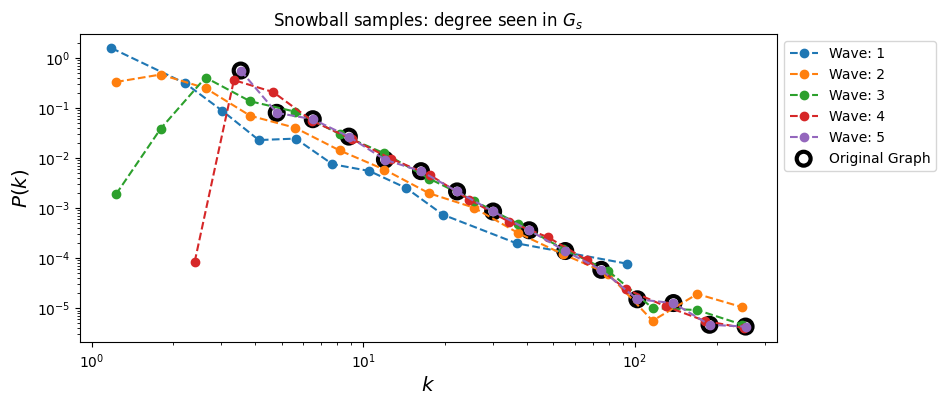

In [48]:
fig, ax = plt.subplots(1,1,figsize=(9, 4), dpi=100)

n = 50  # Number of seed nodes
n_waves = 5  # Maximum number of waves
degrees_sampled = [None] * (n_waves + 1)

nodes = list(G.nodes())

# Perform snowball sampling for increasing numbers of waves
for k in range(n_waves + 1):
    # Select seed nodes randomly
    seed_nodes = set(np.random.choice(nodes, size=n, replace=False))
    
    # Perform snowball sampling
    G_s = snowball_sampling(G, seed_nodes, n_waves=k)
    
    # Print summary of the sampled graph
    print(f"Number of waves: {k} | Number of nodes discovered: {G_s.number_of_nodes()} | "
          f"Number of edges discovered: {G_s.number_of_edges()}")
    
    # Get degree distribution of the sampled graph
    degrees_sampled[k] = [deg for _, deg in G_s.degree()]
    
    # Plot degree distribution for the current wave
    if k > 0:
        x1, y1 = get_binning(degrees_sampled[k], log_binning=True, num_bins=15, is_pmf=False)
        ax.loglog(x1, y1, '--o', label=f'Wave: {k}')

# Plot the degree distribution of the original graph
x, y = get_binning(degrees, log_binning=True, num_bins=15, is_pmf=False)
ax.scatter(x, y, s=100, facecolors='none', edgecolors='k', lw=3, label='Original Graph')

ax.set_title('Snowball samples: degree seen in $G_s$')
ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_xlabel(r'$k$',fontsize='x-large')
ax.set_ylabel(r'$P(k)$',fontsize='x-large')


plt.show()

What does each wave add? Let's run the waves by hand, and keep track of the nodes first found in each wave.

<k> = 6.0, mean degree of wave 1 = 16.4, <k^2>/<k> = 18.7


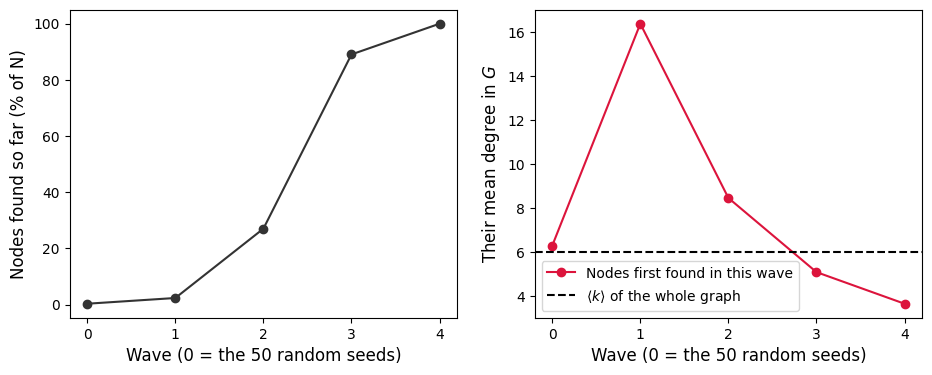

In [49]:
n = 50        # number of seed nodes
n_waves = 4
n_runs = 20

found = np.zeros((n_runs, n_waves + 1))    # share of the nodes found so far, after each wave
mean_k = np.zeros((n_runs, n_waves + 1))   # mean degree in G of the nodes first found in each wave
for r in range(n_runs):
    wave = set(np.random.choice(nodes, size=n, replace=False))
    seen = set(wave)
    for w in range(n_waves + 1):
        found[r, w] = len(seen) / N
        mean_k[r, w] = np.mean([G.degree(u) for u in wave])
        # next wave: neighbors of this wave that we haven't seen yet
        wave = set(v for u in wave for v in G.neighbors(u)) - seen
        seen.update(wave)

k_avg = np.mean(degrees)
k2_avg = np.mean(np.array(degrees)**2)
print('<k> = %.1f, mean degree of wave 1 = %.1f, <k^2>/<k> = %.1f' % (k_avg, mean_k[:, 1].mean(), k2_avg/k_avg))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), dpi=100)
waves = np.arange(n_waves + 1)
ax[0].plot(waves, 100*found.mean(axis=0), 'o-', color='.2')
ax[0].set_ylabel('Nodes found so far (% of N)', fontsize='large')
ax[1].plot(waves, mean_k.mean(axis=0), 'o-', color='crimson', label='Nodes first found in this wave')
ax[1].axhline(k_avg, color='k', ls='--', label=r'$\langle k \rangle$ of the whole graph')
ax[1].set_ylabel('Their mean degree in $G$', fontsize='large')
ax[1].legend()
for a in ax:
    a.set_xlabel('Wave (0 = the %i random seeds)' % n, fontsize='large')
    a.set_xticks(waves)

plt.show()

Wave 1 is the set of neighbors of 50 random nodes, and the neighbor of a random node tends to have more edges than a random node. This is called the **friendship paradox**: on average, your friends have more friends than you do. A node with $k$ edges is a neighbor of $k$ other nodes, so the more edges a node has, the more likely it is to be someone's neighbor. Following a random edge lands on a node of degree $k$ with probability proportional to $k P(k)$, so the mean degree of a neighbor is about $\langle k^2 \rangle / \langle k \rangle$ instead of $\langle k \rangle$. Here, wave 1 has a mean degree about three times $\langle k \rangle$, a bit below $\langle k^2 \rangle / \langle k \rangle$ (both printed above), since a hub that neighbors several seeds is counted only once.

After wave 1 the mean degree drops. Wave 2 is about a quarter of the graph, so it is mostly ordinary nodes, and each hub in it counts only once, however many wave-1 nodes link to it. By the end of wave 2 almost every hub has been found, so the later waves are left with low-degree nodes. By wave 3 the snowball has reached most of the graph.

_____________
## Method 6: Traceroute Sampling
![](images/traceroute_sampling.png)

***Traceroute sampling*** is an example of a _link tracing_ algorithm used to generate sampled graphs. In traceroute sampling, two initial disjoint sets of nodes are drawn at random: a set of _sources_ $V_S$ of size $n_S$ and a set of _targets_ $V_T$ of size $n_T$. Then, a route is traced from each node in $V_S$ to each node in $V_T$ and all vertices and edges encountered are added to $V_s$ and $E_s$, respectively.  Then, the sampled graph is $G_s = (V_s,E_s)$.

If the source and target sets are obtained using a simple random sampling without replacement and the route considered is simply the shortest path between each pair of vertices, then the vertex inclusion probability can be approximated with:

$$ \pi_i \approx 1 - \left(1 - \frac{n_S}{N} - \frac{n_T}{N}\right)\exp\left(-b_i\frac{n_S}{N}\frac{n_T}{N}\right) $$

while the edge inclusion probability can be approximated with:

$$ \pi_{e_{i,j}} \approx 1 - \exp\left(-b_{e_{i,j}}\frac{n_S}{N}\frac{n_T}{N}\right) $$

where $b_i$ is the betweenness centrality of vertex $i$ and $b_{e_{i,j}}$ is the betweenness centrality of edge $e_{i,j}$. 

1. Traceroute sampling can make power laws appear where none existed in the underlying graph (even in the extreme case of regular random graphs)
2. Even when the original degree distribution is power-law, traceroute sampling significantly underestimates the tail exponent

In [50]:
def traceroute_sampling(G, n_sources=5, n_targets=50):
    """
    Perform traceroute sampling on a graph, selecting multiple sources and targets.

    Parameters:
    G : networkx.Graph
        Input graph.
    n_sources : int, optional
        Number of source nodes (default is 5).
    n_targets : int, optional
        Number of target nodes (default is 50).

    Returns:
    networkx.Graph
        A new graph containing the sampled nodes and edges.
    """
    nodes = list(G.nodes())
    shuffle(nodes)

    # Select sources and targets
    sources = set(nodes[:n_sources])
    targets = set(nodes[n_sources:n_sources + n_targets])

    # Initialize the sampled graph
    G_s = nx.Graph() if not G.is_directed() else nx.DiGraph()

    # Compute shortest paths from each source to each target
    for source_node in sources:
        for target_node in targets:
            try:
                path = nx.shortest_path(G, source=source_node, target=target_node)
                G_s.add_nodes_from(path)
                G_s.add_edges_from((path[i], path[i + 1]) for i in range(len(path) - 1))
            except nx.NetworkXNoPath:
                pass  # Ignore if no path exists

    return G_s

In [51]:
N = 2000
k = 15.0
G = nx.erdos_renyi_graph(N, k/(N-1))
degrees = list(dict(G.degree()).values())
M = G.number_of_edges()

G_s_t = traceroute_sampling(G, n_sources=2, n_targets=3)

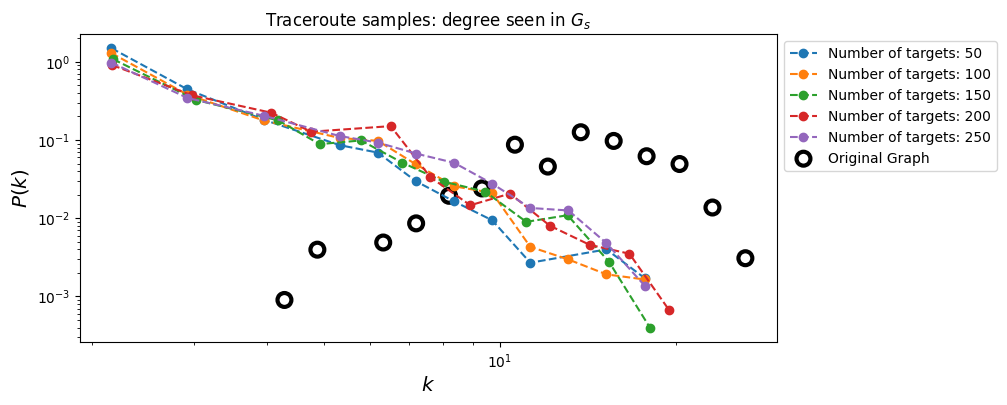

In [52]:
n_sources = 8
share_nodes = []
share_edges = []
sampled_degrees = []

N_targets = np.arange(50,261,50)
for n_targets in N_targets:
    G_s = traceroute_sampling(G, n_sources, n_targets)
    share_nodes.append(G_s.number_of_nodes()/N)
    share_edges.append(G_s.number_of_edges()/M)

    degrees_s = list(dict(G_s.degree()).values())
    
    sampled_degrees.append(degrees_s)

fig, ax = plt.subplots(1,1,figsize=(9, 4), dpi=100)
for k, values in enumerate(sampled_degrees):
    x,y = get_binning(values, log_binning=True, num_bins=15, is_pmf=False)
    ax.loglog(x,y, 'o--', label = "Number of targets: %d" % N_targets[k])

x,y = get_binning(degrees, log_binning=True, num_bins=15, is_pmf=False)
ax.scatter(x,y, s= 100, facecolors='none', edgecolors='k',lw=3,label = "Original Graph")
    
ax.set_title('Traceroute samples: degree seen in $G_s$')
ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_xlabel(r'$k$',fontsize='x-large')
ax.set_ylabel(r'$P(k)$',fontsize='x-large')


plt.show()

Why does an ER graph, where the degrees are bunched around 15, come out looking heavy-tailed? Let's look at one traceroute sample node by node. Below is the same procedure as `traceroute_sampling`, written out so that we know which nodes were the sources.

Sources                  8 nodes, mean degree in G 13.9, mean degree seen in G_s 13.9
1 step from a source   109 nodes, mean degree in G 15.7, mean degree seen in G_s 8.4
2 steps                593 nodes, mean degree in G 16.2, mean degree seen in G_s 3.4
3 or more steps        140 nodes, mean degree in G 14.3, mean degree seen in G_s 4.0


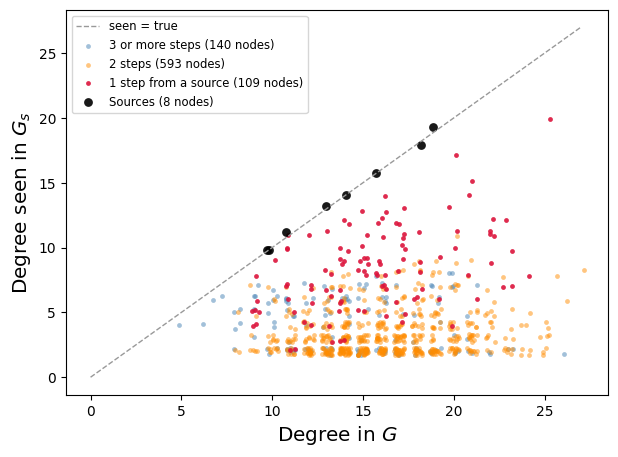

In [53]:
n_sources = 8
n_targets = 150

nodes = list(G.nodes())
shuffle(nodes)
sources = nodes[:n_sources]
targets = nodes[n_sources:n_sources + n_targets]

G_s = nx.Graph()
for source_node in sources:
    for target_node in targets:
        try:
            nx.add_path(G_s, nx.shortest_path(G, source=source_node, target=target_node))
        except nx.NetworkXNoPath:
            pass

# distance from each sampled node to the nearest source (3 means 3 or more)
dist_from_source = [nx.single_source_shortest_path_length(G, s) for s in sources]
V_s = list(G_s.nodes())
dist = np.array([min(min(d.get(u, np.inf) for d in dist_from_source), 3) for u in V_s])
k_true = np.array([G.degree(u) for u in V_s])
k_seen = np.array([G_s.degree(u) for u in V_s])

names = ['Sources', '1 step from a source', '2 steps', '3 or more steps']
colors = ['k', 'crimson', 'darkorange', 'steelblue']
for d in range(4):
    sel = dist == d
    print('%-21s %4i nodes, mean degree in G %.1f, mean degree seen in G_s %.1f'
          % (names[d], sel.sum(), k_true[sel].mean(), k_seen[sel].mean()))

fig, ax = plt.subplots(1, 1, figsize=(7, 5), dpi=100)
ax.plot([0, k_true.max()], [0, k_true.max()], color='.6', ls='--', lw=1, label='seen = true')
for d in [3, 2, 1, 0]:
    sel = dist == d
    # jitter the dots a little so they don't sit on top of each other
    ax.scatter(k_true[sel] + np.random.uniform(-0.3, 0.3, sel.sum()),
               k_seen[sel] + np.random.uniform(-0.3, 0.3, sel.sum()),
               s=40 if d == 0 else 12, color=colors[d], alpha=0.9 if d < 2 else 0.5, lw=0,
               label='%s (%i nodes)' % (names[d], sel.sum()))
ax.set_xlabel('Degree in $G$', fontsize='x-large')
ax.set_ylabel('Degree seen in $G_s$', fontsize='x-large')
ax.legend(loc='upper left', fontsize='small')

plt.show()

Each dot is a node in the traceroute sample, colored by its distance from the nearest source. The sources keep all or nearly all of their edges, because the paths to 150 targets leave through almost every one of their neighbors. Nodes one step from a source keep about half of their edges. Nodes farther away sit on only a few paths and are seen with only a few of their edges, 3 or 4 on average, and they are most of the sample. So $G_s$ is mostly low-degree nodes plus a few well-observed nodes near the sources, which on a log-log plot looks like a heavy tail, even though the degrees in $G$ are bunched around 15.

____________
### Bias reduction in Traceroute Sampling

We can use the _capture-recapture_ estimator to improve the sampled degree distribution (from Flaxman & Vera, 2007). 

The idea is to treat two traceroute samples like the two catches in capture-recapture, and the neighbors of a node $i$ as the population we're counting. Let $G_{u_1}$ and $G_{u_2}$ be two sampled graphs obtained from sources $u_1$ and $u_2$, and let $V_{u}(i)$ be the set of neighbors of node $i$ that appear in $G_u$. If node $i$ is in both samples, we can estimate its degree as:

$$ \hat{k}(i)_{u_1,u_2} = 
\begin{cases} \frac{|V_{u_1}(i)|\times |V_{u_2}(i)|}{|V_{u_1}(i)\cap V_{u_2}(i)|}, & \mbox{if } \left|V_{u_1}(i)\cap V_{u_2}(i)\right|>2 \\ 
\infty, & \mbox{otherwise. } 
\end{cases} $$

Then, we can repeat the same procedure for several pairs of samples and take the median as the final estimate for the degree of node $i$:

$$ \hat{k}(i) = median \left( \left\{ \hat{k}(i)_{u_i,u_j} \neq \infty  \right\} \right) $$

In the formula above, $u_1$ and $u_2$ are single source nodes. The code below pairs up whole traceroute samples instead, each with 10 random sources and 150 targets, matching the first half of the samples with the second half.

**Source:** Flaxman, A. D., & Vera, J. (2007). Bias reduction in traceroute sampling–towards a more accurate map of the internet. In International Workshop on Algorithms and Models for the Web-Graph (pp. 1-15). Berlin, Heidelberg: Springer Berlin Heidelberg. https://link.springer.com/chapter/10.1007/978-3-540-77004-6_1

In [54]:
from collections import defaultdict
from itertools import combinations

def bias_reduction(sampling_method, num_samples, args):
    """
    sampling_method(**args) should return a NetworkX graph G_s
    for each sample (e.g., traceroute sample from some source set).
    """
    # Draw samples (each is a NetworkX graph)
    samples = [sampling_method(**args) for _ in range(num_samples)]
    degrees = defaultdict(list)

    # Pair up samples: first half vs second half
    # (num_samples should be even for this scheme)
    pairs = list(zip(samples[:num_samples // 2], samples[num_samples // 2:]))

    # If you prefer all pairs, use: pairs = combinations(samples, 2)
    for G_s1, G_s2 in pairs:
        # For each node in first sampled graph
        for u in G_s1.nodes():
            if u in G_s2:
                # Neighbors in each sampled graph
                neigh1 = set(G_s1.neighbors(u))
                neigh2 = set(G_s2.neighbors(u))

                N_c = len(neigh1.intersection(neigh2))
                if N_c > 2:
                    # capture–recapture estimator for k(u)
                    degrees[u].append(len(neigh1) * len(neigh2) / N_c)

    # Median estimate per node
    degrees_est = [np.median(values) for node, values in degrees.items()]

    return degrees_est


Nodes with a degree estimate: 367 of 2000


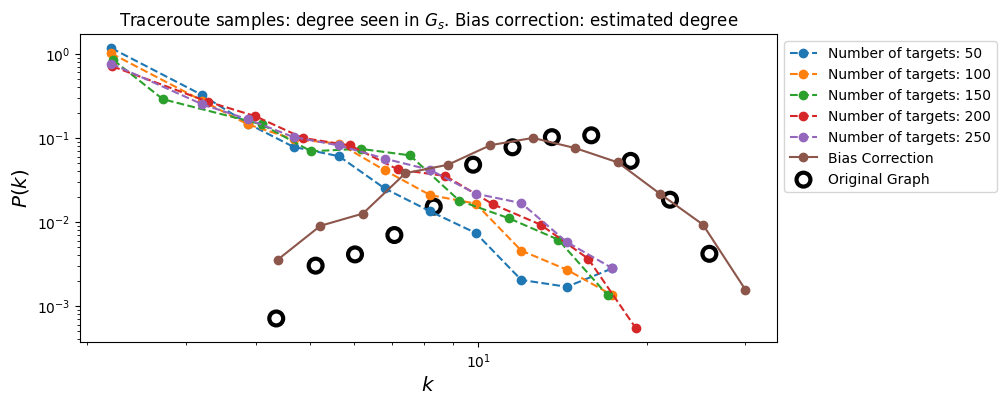

In [55]:
n_sources = 10
n_targets = 150
n_samples = 10

args = {'G':G,'n_sources':n_sources,'n_targets':n_targets}

G_s = traceroute_sampling(G,n_sources,n_targets)
degrees_s = list(dict(G_s.degree()).values())


fig, ax = plt.subplots(1,1,figsize=(9, 4), dpi=100)

# k = N_targets[2]
# values = sampled_degrees[2]
for k, values in enumerate(sampled_degrees):
    x,y = get_binning(values, log_binning=True, num_bins=12, is_pmf=False)
    ax.loglog(x,y, 'o--', label = "Number of targets: %d" % N_targets[k])

degrees_est = bias_reduction(traceroute_sampling, n_samples, args)
print('Nodes with a degree estimate: %i of %i' % (len(degrees_est), N))
    
x,y = get_binning(degrees_est, log_binning=True, num_bins=12, is_pmf=False)
ax.loglog(x,y, '-o', label = "Bias Correction")

x,y = get_binning(degrees, log_binning=True, num_bins=12, is_pmf=False)
ax.scatter(x,y, s= 100, facecolors='none', edgecolors='k',lw=3,label = "Original Graph")



ax.set_title('Traceroute samples: degree seen in $G_s$. Bias correction: estimated degree')
ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_xlabel(r'$k$',fontsize='x-large')
ax.set_ylabel(r'$P(k)$',fontsize='x-large')


plt.show()

A caution about this plot: a node gets a degree estimate only if it shows up in both samples of a pair, with more than 2 of its neighbors seen in both. That's the number printed above, a small part of the graph. So the "Bias Correction" curve describes those nodes, not the whole graph.

There are many more ways to imagine debiasing the sampling procedure!

## Method 7: Random Walk Sampling

***Random Walk sampling*** is another example of a *link tracing* algorithm used to generate sampled graphs. 
The classic algorithm works as follows:
1. We start from a random vertex $i_0$;
2. At each $t_{th}$ step of the walk, given that we are at node $i_t$, we move to one of $i_t$ neighbors with equal probability (i.e. if $k_{i_t}$ is the degree of node $i_t$, we pick one of its neighbors with probability $1/k_{i_t}$).

Then, $V_s$ will include all the nodes visited during the random walk, while $E_s$ will include all the edges traversed. 

As we saw in Class 12, the probability of being at a particular node $i$ converges to the stationary distribution (Class 12 wrote $E$ for the number of edges; here it's $M$):

$$ \pi_i = \frac{k_i}{2M}$$

Notice that this $\pi_i$ is the share of time the walker spends at node $i$, not the inclusion probability from the earlier methods. It is proportional to $k_i$, so a random walk visits high-degree nodes more often: the first problem from the start of class.


In practice, we may allow for the fact that the graph is not connected and that our random walker might get stuck. If that is the case, we can randomly select a different starting node for the remaining steps. Lastly, we can allow for the possibility that the random walker "flies back" to the original node and re-starts walking from there.

In [56]:
def random_walk_sampling(G, n, fly_back=0.0, jump_after=10, v0=None):
    """
    Single-walker random walk sampling on a NetworkX graph.
    Walks until n distinct nodes have been found. With probability fly_back the walker
    jumps back to the start node, and after more than jump_after steps that find nothing
    new it jumps to a random node.
    """
    if G.number_of_nodes() == 0:
        return nx.Graph() if not G.is_directed() else nx.DiGraph()

    nodes = list(G.nodes())

    if v0 is None:
        v0 = np.random.choice(nodes)
        
    V_s = {v0}
    E_s = set()
    stuck = 0
    
    node_t = v0
    nodes_discovered = len(V_s)
    edges_discovered = len(E_s)
    
    while len(V_s) < n:
        if np.random.rand() < fly_back:
            # Fly back to starting node
            node_t = v0
        else:
            neighbors = list(G.neighbors(node_t))
            if neighbors:
                next_node = np.random.choice(neighbors)
                # add the new node and the edge we walked along
                V_s.add(next_node)
                edge = (node_t, next_node) if node_t < next_node else (next_node, node_t)
                E_s.add(edge)
                node_t = next_node
            else:
                # no neighbors: we rely on stuck logic and teleports
                next_node = node_t  # no move

        # stuck logic: did we discover anything new?
        if (nodes_discovered == len(V_s)) and (edges_discovered == len(E_s)):
            stuck += 1
        else:
            stuck = 0

        nodes_discovered = len(V_s)
        edges_discovered = len(E_s)

        if stuck > jump_after:
            node_t = np.random.choice(nodes)
            V_s.add(node_t)
            stuck = 0
        
    # Build sampled graph
    G_s = nx.Graph() if not G.is_directed() else nx.DiGraph()
    G_s.add_nodes_from(V_s)
    G_s.add_edges_from(E_s)

    return G_s


In [57]:
N = 10000
m = 3
seed = 4
G = nx.barabasi_albert_graph(N, m, seed=seed)

# original degrees in the full graph
degrees_full_dict = dict(G.degree())
degrees_full = list(degrees_full_dict.values())

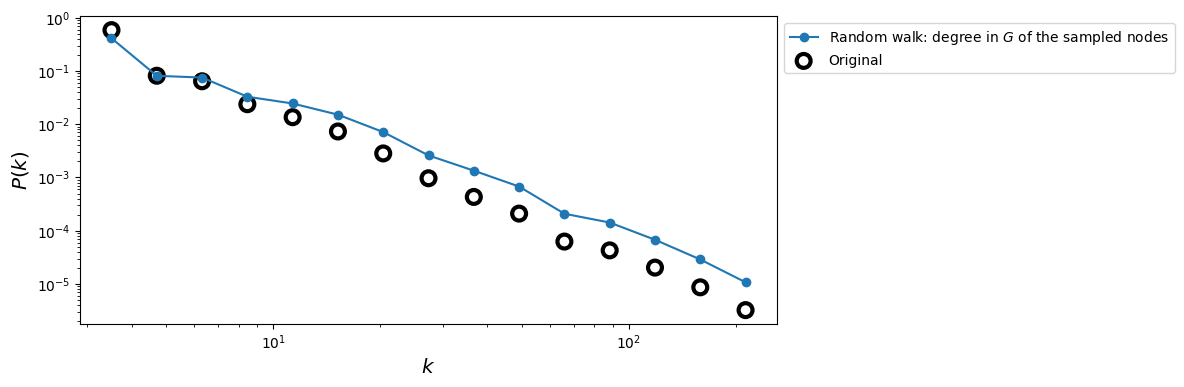

In [58]:
n = 3000
fly_back = 0.0

fig, ax = plt.subplots(1,1,figsize=(9, 4), dpi=100)

# sample with RW
G_s = random_walk_sampling(G, n, fly_back=fly_back)
V_s = list(G_s.nodes())

# degrees of sampled nodes in the *original* graph
deg_sampled_original = [degrees_full_dict[u] for u in V_s]

# binned curves
x, y = get_binning(deg_sampled_original,
                   log_binning=True, num_bins=15, is_pmf=False)
ax.loglog(x, y, marker='o', label='Random walk: degree in $G$ of the sampled nodes')

x0, y0 = get_binning(degrees_full, num_bins=15,
                     log_binning=True, is_pmf=False)
ax.scatter(x0, y0, s=100, facecolors='none', edgecolors='k', lw=3,
            label='Original')

ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_xlabel(r'$k$',fontsize='x-large')
ax.set_ylabel(r'$P(k)$',fontsize='x-large')


plt.show()

______
### Re-Weighted Random Walk
One way to correct the bias towards high node degrees of the classic random walk is to _re-weight_ the observed degree distribution _after_ running the random walk. Let $i_1, i_2, \dots, i_T$ be the nodes the walker is at after each of its $T$ steps, counting repeat visits. Then

$$ \hat{p}(k) = \frac{\sum_{\{t \,|\, k_{i_t} = k \}} 1/k_{i_t}  }{\sum_{t=1}^{T} 1/k_{i_t}  } .$$

The walker is at node $i$ in proportion to $k_i$, so giving each visit a weight $1/k_i$ cancels that out. This only works over the full sequence of visits. Over the set of distinct nodes $V_s$, each node counts once however often it was visited, so the $1/k_i$ weights over-correct.

### Metropolis-Hastings Random Walk Sampling

The classic random walk sampling algorithm is biased towards high degree nodes. One way to correct for this bias is to use Metropolis-Hastings random walk sampling.

***Metropolis-Hastings random walk sampling*** algorithm works as follows:
1. we start from a random vertex $i_0$;
2. at each $t_{th}$ step of the walk, given that we are at node $i_t$, we select at random one of $i_t$ neighbors (let us denote this node with $w$);
3. we generate a random number $0\leq r \leq 1$;
4. if $r \leq \frac{k_{i_t}}{k_{w}}$ then we accept the move, otherwise we stay at node $i_t$ (staying counts as a step, so $i_{t+1} = i_t$) and we go back to 2.


This is the Metropolis idea from Class 9, where we used it to walk over partitions of a network: propose a move, then accept or reject it, so that over a long run the walk spends the right share of time in each state. Here the states are nodes, and the acceptance rule $k_{i_t}/k_w$ makes the share of time the walker spends at each node converge to the uniform distribution, $1/N$. That holds for the visits, counting repeats, not for the set of distinct nodes the walker has found.

In [59]:
def metropolis_hastings_random_walk_sampling(G, n, fly_back=0.0, jump_after=10, v0=None):
    """
    Single-walker Metropolis–Hastings random walk sampling on a NetworkX graph.

    How it works:
    - start from v0 (or a random node),
    - propose a random neighbor,
    - accept with probability deg(curr) / deg(next),
    - use 'fly_back' and 'jump_after' as in random_walk_sampling.
    """
    if G.number_of_nodes() == 0:
        return nx.Graph() if not G.is_directed() else nx.DiGraph()

    nodes = list(G.nodes())

    if v0 is None:
        v0 = np.random.choice(nodes)

    V_s = {v0}
    E_s = set()
    stuck = 0

    node_t = v0
    nodes_discovered = len(V_s)
    edges_discovered = len(E_s)

    while len(V_s) < n:
        if np.random.rand() < fly_back:
            # fly back to the starting node (no edge added)
            node_t = v0
        else:
            neighbors = list(G.neighbors(node_t))
            if neighbors:
                candidate = np.random.choice(neighbors)
                deg_curr = G.degree(node_t)
                deg_next = G.degree(candidate)

                if deg_next > 0:
                    if np.random.rand() < deg_curr / float(deg_next):
                        # accept move
                        V_s.add(candidate)
                        edge = (node_t, candidate) if node_t < candidate else (candidate, node_t)
                        E_s.add(edge)
                        node_t = candidate

            # stuck logic: did we discover anything new this iteration?
            if (nodes_discovered == len(V_s)) and (edges_discovered == len(E_s)):
                stuck += 1
            else:
                stuck = 0

            nodes_discovered = len(V_s)
            edges_discovered = len(E_s)

        if stuck > jump_after:
            # teleport to a random node
            node_t = np.random.choice(nodes)
            V_s.add(node_t)
            stuck = 0

    G_s = nx.Graph() if not G.is_directed() else nx.DiGraph()
    G_s.add_nodes_from(V_s)
    G_s.add_edges_from(E_s)

    return G_s


### Checking the two corrections

`random_walk_sampling` and `metropolis_hastings_random_walk_sampling` return the set of distinct nodes the walker found, which is what we'd keep as a sample. To use the re-weighting formula, and to check the Metropolis-Hastings claim, we need every step of the walk, counting repeat visits. `walk_visits` below records the node the walker is at after each step.

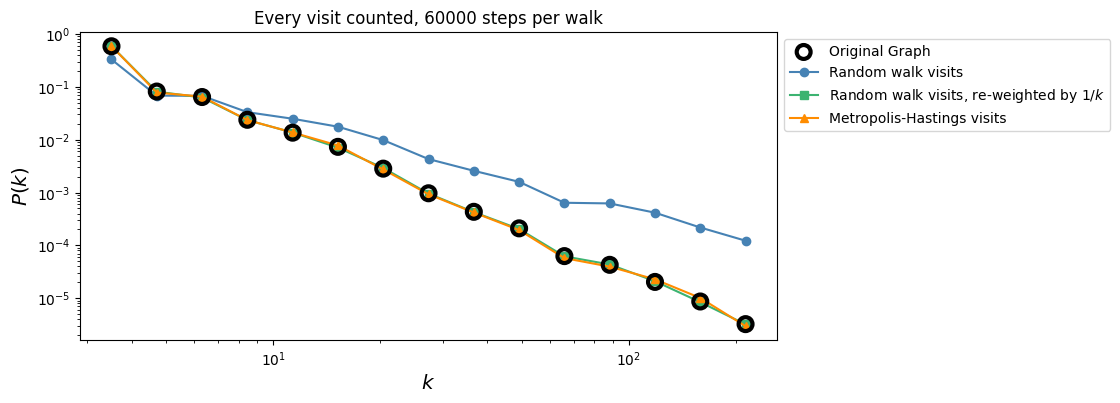

Mean degree in G:                         6.00
Random walk visits:                       17.48
Random walk visits, re-weighted by 1/k:   5.98
Metropolis-Hastings visits:               5.97
Distinct nodes from metropolis_hastings_random_walk_sampling(G, 2000): 7.47


In [60]:
def walk_visits(G, T, metropolis=False):
    """
    Run a single walker for T steps and return the node it is at after each step
    (repeat visits counted).
    metropolis=False: plain random walk, always move to a random neighbor.
    metropolis=True: Metropolis-Hastings, move with probability k_now / k_candidate.
    """
    nodes = list(G.nodes())
    node = np.random.choice(nodes)
    visits = []
    for t in range(T):
        candidate = np.random.choice(list(G.neighbors(node)))
        if not metropolis or np.random.rand() < G.degree(node) / G.degree(candidate):
            node = candidate
        visits.append(node)
    return visits


T = 60000
k_rw = np.array([degrees_full_dict[u] for u in walk_visits(G, T)])
k_mh = np.array([degrees_full_dict[u] for u in walk_visits(G, T, metropolis=True)])

# get_binning doesn't take weights, so we bin with np.histogram directly, with the same log bins for every curve
bin_edges = np.logspace(np.log10(min(degrees_full)), np.log10(max(degrees_full)), 16)
centers = bin_edges[1:] - np.diff(bin_edges) / 2

def binned(values, weights=None):
    p, _ = np.histogram(values, bins=bin_edges, weights=weights, density=True)
    return centers[p > 0], p[p > 0]

fig, ax = plt.subplots(1, 1, figsize=(9, 4), dpi=100)
x, y = binned(degrees_full)
ax.scatter(x, y, s=100, facecolors='none', edgecolors='k', lw=3, label='Original Graph', zorder=3)
x, y = binned(k_rw)
ax.loglog(x, y, 'o-', color='steelblue', label='Random walk visits')
x, y = binned(k_rw, weights=1/k_rw)
ax.loglog(x, y, 's-', color='mediumseagreen', label='Random walk visits, re-weighted by $1/k$')
x, y = binned(k_mh)
ax.loglog(x, y, '^-', color='darkorange', label='Metropolis-Hastings visits')
ax.set_title('Every visit counted, %i steps per walk' % T)
ax.legend(loc=2,bbox_to_anchor=[1.0,1.0])
ax.set_xlabel(r'$k$',fontsize='x-large')
ax.set_ylabel(r'$P(k)$',fontsize='x-large')

plt.show()

G_mh = metropolis_hastings_random_walk_sampling(G, 2000)
print('Mean degree in G:                         %.2f' % np.mean(degrees_full))
print('Random walk visits:                       %.2f' % np.mean(k_rw))
print('Random walk visits, re-weighted by 1/k:   %.2f' % (np.sum(k_rw/k_rw) / np.sum(1/k_rw)))
print('Metropolis-Hastings visits:               %.2f' % np.mean(k_mh))
print('Distinct nodes from metropolis_hastings_random_walk_sampling(G, 2000): %.2f'
      % np.mean([degrees_full_dict[u] for u in G_mh.nodes()]))

The plain walk (blue) is hub-heavy, because it spends time at node $i$ in proportion to $k_i$. Weighting each visit by $1/k_i$ cancels that, and the green curve lands on the original. Metropolis-Hastings gets there differently: it rejects some moves toward higher-degree nodes, so its visits are already spread evenly over the nodes (orange), with no re-weighting.

The last number printed above is a caution. The *set* of distinct nodes from `metropolis_hastings_random_walk_sampling` still has a higher mean degree than the graph. At a low-degree node, most proposed moves go to a neighbor with a higher degree and many of them are rejected, so the walker often stays put for several steps in a row. Those visits pile up on fewer distinct nodes, so the distinct set ends up with relatively more hubs.

__________
## Summary

| Method | What is picked at random | Who is over-represented | Probability that node $i$ is in the sample (for walks, its share of the visits) |
|---|---|---|---|
| Induced subgraph | $n$ nodes | nobody, but each node keeps only about $n/N$ of its edges | $\pi_i = n/N$ |
| Incident subgraph | $n$ edges | high-degree nodes | $\pi_i = 1 - \binom{M-k_i}{n} / \binom{M}{n}$ |
| Edge sampling with induction | $n$ edges, then every edge among their endpoints | high-degree nodes | same as incident |
| Star (labeled) | $n$ starting nodes, with all their edges and neighbors | high-degree nodes | $\pi_i = 1 - \binom{N-1-k_i}{n} / \binom{N}{n}$ |
| Snowball | seed nodes | high-degree nodes, in the early waves | no simple formula |
| Traceroute | sources and targets | nodes on many shortest paths | approximated from betweenness |
| Random walk | a starting node | high-degree nodes | $\to k_i/2M$ |
| Metropolis-Hastings walk | a starting node | nobody, counting repeat visits | $\to 1/N$ |

__________
## Next time...
Machine Learning 1: General & Link Prediction `class_18_machine_learning1.ipynb` (Wed, Nov 18)
_______

## References and further resources:

1. Class Webpages
    - Jupyter Book: https://computational-methods-network-science.github.io/nets7052_fa26/README.html
    - Github: https://github.com/computational-methods-network-science/nets7052_fa26/
    - Syllabus and course details: https://brennanklein.com/nets7052-fall26
2. Achlioptas, D., Clauset, A., Kempe, D., & Moore, C. (2009). On the bias of traceroute sampling: Or, power-law degree distributions in regular graphs. Journal of the ACM (JACM), 56(4), 21.
3. Ahmed, N. K., Neville, J., & Kompella, R. (2014). Network sampling: From static to streaming graphs. ACM Transactions on Knowledge Discovery from Data (TKDD), 8(2), 7.
4. Dall'Asta, L., Alvarez-Hamelin, I., Barrat, A., Vazquez, A., & Vespignani, A. (2004). A statistical approach to the traceroute-like exploration of networks: theory and simulations. arXiv preprint cond-mat/0406404.
5. Flaxman, A. D., & Vera, J. (2007). Bias Reduction in Traceroute Sampling–Towards a More Accurate Map of the Internet. In Algorithms and Models for the Web-Graph (pp. 1-15). Springer Berlin Heidelberg.
6. Gjoka, M., Kurant, M., Butts, C. T., & Markopoulou, A. (2010, March). Walking in Facebook: A case study of unbiased sampling of OSNs. In INFOCOM, 2010 Proceedings IEEE (pp. 1-9). IEEE.
7. Leskovec, J., & Faloutsos, C. (2006, August). Sampling from large graphs. In Proceedings of the 12th ACM SIGKDD international conference on Knowledge discovery and data mining (pp. 631-636). ACM.
8. Leskovec, J., Kleinberg, J., & Faloutsos, C. (2005, August). Graphs over time: densification laws, shrinking diameters and possible explanations. In Proceedings of the eleventh ACM SIGKDD international conference on Knowledge discovery in data mining (pp. 177-187). ACM.
9. Lovász, L. (1996). Random walks on graphs: A survey. Combinatorics, Paul Erdos is Eighty, 2, 353-398.
10. Kolaczyk, E. (2009). Statistical Analysis of Network Data: Methods and Models. Springer Series in Statistics.